# EDA — Commandes ZAHAN

Ce notebook explore le fichier `zahan_data-1793114482467.csv` : des lignes de commandes de boissons et de quelques plats, confirmées en octobre 2026. Les montants sont exprimés dans l'unité du fichier, sans doute le franc CFA (FCFA).

L'ordre suit l'analyse : qualité des données, univarié, bivarié, multivarié, puis synthèse. Chaque niveau associe un graphique à un test statistique. Les constats décrivent des associations, pas des causes. Aucun modèle n'est entraîné.

## 1. Qualité des données

### 1.1 Structure

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import stats
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

BLEU, ORANGE, VERT, JAUNE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TEXTE, TEXTE_2, GRILLE, FOND, NEUTRE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b9b8b3"
RAMPE = LinearSegmentedColormap.from_list("rampe", ["#f3f7fc", BLEU, "#123a6b"])
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", [BLEU, "#f1f0ed", ORANGE])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 9,
})

brut = pd.read_csv("zahan_data-1793114482467.csv")
print(brut.shape)
display(brut.head())
display(pd.DataFrame({"type": brut.dtypes.astype(str), "manquants": brut.isna().sum(),
                      "valeurs distinctes": brut.nunique()}))

(2633, 6)


,n_commande,montant_total,date_confirmation_reception,montant_unitaire,produit,quantite
0,CW0010480,1000.0,2026-10-18 01:03:16.351 +0100,1000.0,Awoyo 65cl (Grande),1
1,CW0012419,1200.0,2026-10-23 04:09:16.070 +0100,600.0,Eku 33cl (Petite),2
2,CW0016703,500.0,2026-10-21 00:20:39.934 +0100,500.0,Eau Fifa 1.5L (Grande),1
3,CW0026261,500.0,2026-10-25 19:02:40.315 +0100,500.0,SUCRERIE GRAND,1
4,CW0026931,700.0,2026-10-24 19:15:41.965 +0100,350.0,MaltaTonic,2


,type,manquants,valeurs distinctes
n_commande,str,0,2133
montant_total,float64,0,70
date_confirmation_reception,str,15,2127
montant_unitaire,float64,0,17
produit,str,0,77
quantite,int64,0,13


In [2]:
brut["date"] = pd.to_datetime(brut["date_confirmation_reception"], format="%Y-%m-%d %H:%M:%S.%f %z")
print("Fuseaux horaires :", brut["date_confirmation_reception"].str[-5:].value_counts(dropna=False).to_dict())
print("Période :", brut["date"].min(), "->", brut["date"].max())
print("Lignes dupliquées :", brut.duplicated().sum())
print("Même produit deux fois dans une commande :", brut.duplicated(["n_commande", "produit"]).sum())

lignes_par_commande = brut.groupby("n_commande").size()
print("Commandes :", lignes_par_commande.size, "| lignes par commande :", lignes_par_commande.value_counts().sort_index().to_dict())

controle = brut.assign(sous_total=brut["montant_unitaire"] * brut["quantite"]).groupby("n_commande").agg(
    total=("montant_total", "first"), totaux_differents=("montant_total", "nunique"),
    somme_lignes=("sous_total", "sum"), dates_differentes=("date", "nunique"))
print("Commandes avec plusieurs montant_total :", (controle["totaux_differents"] > 1).sum())
print("Commandes avec plusieurs dates :", (controle["dates_differentes"] > 1).sum())
print("montant_total = somme(prix x quantité) :", f"{(controle['total'] == controle['somme_lignes']).mean():.1%}")

Fuseaux horaires : {'+0100': 2618, nan: 15}
Période : 2026-10-05 20:05:37.696000+01:00 -> 2026-10-27 15:31:03.674000+01:00
Lignes dupliquées : 0
Même produit deux fois dans une commande : 0
Commandes : 2133 | lignes par commande : {1: 1746, 2: 297, 3: 71, 4: 15, 5: 4}
Commandes avec plusieurs montant_total : 0
Commandes avec plusieurs dates : 0
montant_total = somme(prix x quantité) : 100.0%


Une ligne correspond à un produit dans une commande : 2 633 lignes pour 2 133 commandes, et 81,9 % des commandes ne contiennent qu'un seul produit. `montant_total` est porté par la commande et répété sur chacune de ses lignes. Il vaut exactement la somme des prix × quantités dans 100 % des commandes. Il n'y a ni doublon, ni produit répété dans une même commande, ni commande avec deux dates. Toutes les dates sont dans le même fuseau (+01:00).

**Conséquence pour la suite :** il y a deux niveaux d'analyse. Les produits, les prix et les quantités se lisent par ligne. Le panier et l'heure se lisent par commande : compter `montant_total` ligne par ligne donnerait plus de poids aux grosses commandes.

### 1.2 Dates manquantes

In [3]:
sans_date = brut[brut["date"].isna()]
print(f"{len(sans_date)} lignes sans date, dans {sans_date['n_commande'].nunique()} commandes")
display(sans_date[["n_commande", "produit", "montant_unitaire", "quantite", "montant_total"]])

15 lignes sans date, dans 6 commandes


,n_commande,produit,montant_unitaire,quantite,montant_total
337,CW1313102,Akassa + Monton,1300.0,1,6500.0
338,CW1313102,Akassa + Boeuf,1300.0,1,6500.0
339,CW1313102,Akassa + Poisson,1300.0,3,6500.0
408,CW1675451,La Beninoise 33cl,350.0,2,700.0
497,CW2023152,La Beninoise 33cl,350.0,1,350.0
1420,CW5494836,La Beninoise 33cl,350.0,1,1350.0
1421,CW5494836,Pils Benin 33cl,400.0,1,1350.0
1422,CW5494836,La Beninoise 65cl,600.0,1,1350.0
2172,CW8432725,Kanpke 65cl,600.0,2,4750.0
2173,CW8432725,La Beninoise 33cl,350.0,2,4750.0


Les 15 lignes sans date forment 6 commandes entières : la date manque pour toute la commande, jamais pour une seule ligne. Leurs libellés n'ont pas le suffixe `(Petite)` ou `(Grande)` du reste du catalogue, et `Kanpke` y est écrit avec une autre orthographe que `Kankpe`. Je teste si l'absence de date est liée à cette ancienne forme des libellés.

In [4]:
avec_suffixe = brut["produit"].str.contains(r"\(", regex=True)
table_manquant = pd.crosstab(brut["date"].isna(), avec_suffixe).reindex(index=[True, False], columns=[False, True])
table_manquant.index, table_manquant.columns = ["date manquante", "date présente"], ["sans suffixe", "avec suffixe"]
display(table_manquant)
print(stats.fisher_exact(table_manquant.to_numpy()))

anciens = brut.loc[~avec_suffixe & brut["date"].notna()]
print("Lignes sans suffixe mais datées :", len(anciens))

,sans suffixe,avec suffixe
date manquante,15,0
date présente,579,2039


SignificanceResult(statistic=inf, pvalue=np.float64(1.7377329859106425e-10))
Lignes sans suffixe mais datées : 579


Le test exact de Fisher rejette nettement l'indépendance (p < 1e-10) : les 15 lignes sans date sont toutes sans suffixe, alors que 78 % des lignes datées en ont un. L'absence de date n'est donc pas aléatoire. Elle touche une partie du catalogue écrite à l'ancienne. Une imputation ne serait pas fiable : ces lignes sont gardées pour les analyses sans dimension temporelle, et exclues des analyses de temps.

### 1.3 Commande suspecte

In [5]:
display(brut.loc[brut["montant_unitaire"] > 2000, ["n_commande", "produit", "montant_unitaire", "quantite", "montant_total", "date"]])
display(brut[brut["n_commande"] == "CW1213050"][["n_commande", "produit", "montant_unitaire", "quantite", "montant_total"]])

,n_commande,produit,montant_unitaire,quantite,montant_total,date
309,CW1213050,3 La Beninoise 33cl (3 Petites),9771.0,1,11005.0,2026-10-08 16:42:45.958000+01:00
891,CW3514872,Vin Blanc / Rouge 5k,5000.0,1,5000.0,2026-10-13 17:51:51.321000+01:00


,n_commande,produit,montant_unitaire,quantite,montant_total
309,CW1213050,3 La Beninoise 33cl (3 Petites),9771.0,1,11005.0
310,CW1213050,Test Park,1234.0,1,11005.0


La commande `CW1213050` contient le produit `Test Park` à 1 234 et un pack `3 La Beninoise 33cl (3 Petites)` à 9 771, alors que trois petites La Beninoise valent environ 1 050. Ces deux montants ne sont pas des prix réels : c'est une commande de test. **Décision : la retirer.** Le vin à 5 000 est en revanche cohérent avec son libellé `Vin Blanc / Rouge 5k`, et il est gardé.

### 1.4 Libellés des produits

In [6]:
donnees = brut[brut["n_commande"] != "CW1213050"].copy()

liste = donnees.groupby("produit").agg(lignes=("produit", "size"), prix=("montant_unitaire", lambda s: sorted(s.unique())))
print("Libellés avec des espaces en trop :", [p for p in liste.index if p != p.strip()])
cles = liste.index.str.strip().str.lower()
groupes = pd.Series(liste.index, index=cles).groupby(level=0).agg(list)
print("Libellés identiques sans la casse ni les espaces :", groupes[groupes.str.len() > 1].tolist())

for a, b in [("Kankpe 65cl (Grande)", "Kanpke 65cl (Grande)"), ("Kankpe 33cl (Petite)", "Kanpke 33cl (Petite)")]:
    ga, gb = donnees[donnees["produit"] == a], donnees[donnees["produit"] == b]
    jours = lambda g: set((g["date"] - pd.Timedelta(hours=6)).dt.date.dropna())
    print(f"{a} : {len(ga)} lignes, prix {ga['montant_unitaire'].value_counts().to_dict()}")
    print(f"{b} : {len(gb)} lignes, prix {gb['montant_unitaire'].value_counts().to_dict()}")
    print(f"  jours en commun : {len(jours(ga) & jours(gb))} sur {len(jours(ga) | jours(gb))}")
    print("  commandes contenant les deux :", len(set(ga["n_commande"]) & set(gb["n_commande"])))

Libellés avec des espaces en trop : ['Eau Comtesse ', 'Tequila ', 'dopel Energy ']
Libellés identiques sans la casse ni les espaces : [['EAU COMTESSE', 'Eau Comtesse '], ['EAU KWABO', 'Eau Kwabo'], ['Tequila ', 'tequila']]
Kankpe 65cl (Grande) : 104 lignes, prix {600.0: 93, 700.0: 11}
Kanpke 65cl (Grande) : 106 lignes, prix {600.0: 106}


  jours en commun : 11 sur 18
  commandes contenant les deux : 0
Kankpe 33cl (Petite) : 69 lignes, prix {350.0: 66, 400.0: 3}
Kanpke 33cl (Petite) : 11 lignes, prix {350.0: 11}
  jours en commun : 5 sur 17
  commandes contenant les deux : 0


Le catalogue est sale. Trois libellés finissent par un espace, et plusieurs produits apparaissent sous deux écritures qui ne diffèrent que par la casse, l'espace final ou le suffixe de format. `Kankpe` et `Kanpke` désignent la même bière : mêmes formats, même prix de base, et des jours de vente en grande partie communs (11 soirées sur 18 pour la 65cl). Ils ne sont jamais dans la même commande, ce qui est attendu pour deux fiches du même produit.

Une différence est à noter : `Kankpe 65cl (Grande)` passe 11 fois à 700, `Kanpke 65cl (Grande)` jamais. Les deux fiches n'appliquent donc pas toujours le même tarif (voir section 3.1).

**Décision :** regrouper les libellés par une clé commune (espaces, casse, suffixe de format, orthographe de Kankpe et de Doppel). Deux variables sont dérivées des noms : le **format** (petit ou grand, d'après le volume ou le mot du libellé) et la **catégorie**. La catégorie est une lecture des noms de marques connues au Bénin, pas une donnée du fichier.

In [7]:
import re

def cle_produit(libelle):
    """Clé commune à toutes les écritures d'un même produit."""
    texte = libelle.strip().lower()
    texte = re.sub(r"\((grande|petite)\)|bouteille", "", texte)
    texte = texte.replace("kanpke", "kankpe").replace("dopel", "doppel").replace("bb pils lager", "bb lager")
    texte = re.sub(r"(\d)\s+cl", r"\1cl", texte)
    return re.sub(r"\s+", " ", texte).strip()


def format_produit(libelle):
    texte = libelle.lower()
    volume = re.search(r"(\d+(?:\.\d+)?)\s*(cl|l)\b", texte)
    if volume:
        cl = float(volume.group(1)) * (100 if volume.group(2) == "l" else 1)
        return "grand" if cl >= 50 else "petit"
    if "grand" in texte:
        return "grand"
    if "petit" in texte:
        return "petit"
    return "non précisé"


CATEGORIES = {
    "eau": "eau", "posso": "eau",
    "akassa": "plat", "spaghetti": "plat", "riz": "plat", "ndomie": "plat",
    "youki": "soda", "sucrerie": "soda", "cola": "soda", "sprite": "soda", "malta": "soda", "tonic": "soda",
    "xxl": "énergisant", "doppel energy": "énergisant", "rox": "énergisant",
    "vodys": "autre alcool", "tequila": "autre alcool", "vin": "autre alcool", "savana": "autre alcool",
}


def categorie(cle):
    for mot, nom in CATEGORIES.items():
        if re.search(rf"\b{mot}", cle):
            return nom
    return "bière"


donnees["cle"] = donnees["produit"].map(cle_produit)
nom_retenu = donnees.groupby("cle")["produit"].agg(lambda s: s.str.strip().value_counts().index[0].replace("Kanpke", "Kankpe"))
donnees["produit_net"] = donnees["cle"].map(nom_retenu)
donnees["format"] = donnees["produit"].map(format_produit)
donnees["categorie"] = donnees["cle"].map(categorie)

print(f"{donnees['produit'].nunique()} libellés -> {donnees['produit_net'].nunique()} produits")
regroupes = donnees.groupby("produit_net")["produit"].agg(lambda s: sorted(s.unique()))
display(regroupes[regroupes.str.len() > 1].to_frame("libellés regroupés"))
display(donnees.groupby("categorie")["produit_net"].agg(lambda s: ", ".join(sorted(s.unique()))).to_frame("produits"))
print(pd.crosstab(donnees["categorie"], donnees["format"], margins=True))

75 libellés -> 61 produits


,libellés regroupés
produit_net,
BB Lager grand,"[BB Lager grand, BB PILS LAGER GRAND]"
Castel Beer 65cl (Grande),"[Castel Beer 65cl, Castel Beer 65cl (Grande)]"
Doppel Energy,"[Doppel Energy, dopel Energy ]"
EAU COMTESSE,"[EAU COMTESSE, Eau Comtesse ]"
EAU KWABO,"[EAU KWABO, Eau Kwabo]"
Flag 65cl (Grande),"[Flag 65cl, Flag 65cl (Grande)]"
Kankpe 33cl (Petite),"[Kankpe 33cl (Petite), Kanpke 33cl, Kanpke 33cl (Petite)]"
Kankpe 65cl (Grande),"[Kankpe 65cl (Grande), Kanpke 65cl, Kanpke 65cl (Grande)]"
La Beninoise 33cl (Petite),"[La Beninoise 33cl, La Beninoise 33cl (Petite)]"


,produits
categorie,
autre alcool,"SAVANA, Vin Blanc / Rouge 5k, tequila, vin de palme, vodys"
bière,"3 La Beninoise 33cl, Awoyo 65cl (Grande), BB Lager grand, BB Lager petit, Beaufort 33cl (Petite), Beaufort 65cl (Gra..."
eau,"EAU COMTESSE, EAU KWABO, Eau Aqua belle, Eau Fifa 1.5L (Grande), Eau Possotome 1.5L (Grande), Posso citron, Possotom..."
plat,"Akassa + Boeuf, Akassa + Monton, Akassa + Poisson, Ndomie personnel, Riz au Gras, Spaghetti Blanche, Spaghetti Rouge"
soda,"Coca-Cola 33 cl Bouteille (Petite), MaltaTonic, SUCRERIE GRAND, SUCRERIE PETIT, Sprite 33 cl Bouteille (Petite), Spr..."
énergisant,"Doppel Energy, ROX, XXL"


format        grand  non précisé  petit   All
categorie                                    
autre alcool      0          143      0   143
bière          1387           11    551  1949
eau              77           81      0   158
plat              0           15      0    15
soda            128           15     95   238
énergisant        0          128      0   128
All            1592          393    646  2631


Les 75 libellés se réduisent à 61 produits. La bière représente 74 % des lignes (1 949 sur 2 631). Viennent ensuite les sodas (238), l'eau (158), les autres alcools (143), les énergisants (128) et les plats (15). Le format n'est pas indiqué pour 393 lignes : autres alcools, énergisants et une partie des eaux.

### 1.5 Variables de temps et période d'étude

L'activité se prolonge après minuit : une commande passée le samedi à 1 h appartient à la soirée du vendredi. Chaque commande est donc rattachée à une **soirée**, qui va de 6 h à 6 h le lendemain.

In [8]:
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

donnees["soiree"] = (donnees["date"] - pd.Timedelta(hours=6)).dt.normalize().dt.tz_localize(None)
donnees["jour"] = pd.Categorical(donnees["soiree"].dt.dayofweek.map(dict(enumerate(JOURS))), categories=JOURS, ordered=True)
donnees["heure"] = donnees["date"].dt.hour + donnees["date"].dt.minute / 60

par_soiree = donnees.dropna(subset=["date"]).groupby("soiree").agg(
    commandes=("n_commande", "nunique"), premiere=("date", "min"), derniere=("date", "max"))
par_soiree["jour"] = par_soiree.index.dayofweek.map(dict(enumerate(JOURS)))
display(par_soiree)

,commandes,premiere,derniere,jour
soiree,,,,
2026-10-05,1,2026-10-05 20:05:37.696000+01:00,2026-10-05 20:05:37.696000+01:00,lundi
2026-10-07,1,2026-10-07 18:51:30.872000+01:00,2026-10-07 18:51:30.872000+01:00,mercredi
2026-10-08,4,2026-10-08 16:42:03.806000+01:00,2026-10-09 05:27:58.918000+01:00,jeudi
2026-10-09,64,2026-10-09 15:32:41.805000+01:00,2026-10-10 03:16:34.165000+01:00,vendredi
2026-10-10,149,2026-10-10 11:00:14.817000+01:00,2026-10-11 04:47:45.438000+01:00,samedi
2026-10-11,120,2026-10-11 11:36:03.076000+01:00,2026-10-12 04:19:35.873000+01:00,dimanche
2026-10-12,53,2026-10-12 12:25:09.351000+01:00,2026-10-13 02:27:09.692000+01:00,lundi
2026-10-13,100,2026-10-13 09:34:11.743000+01:00,2026-10-14 03:13:37.942000+01:00,mardi
2026-10-14,143,2026-10-14 07:38:04.684000+01:00,2026-10-15 02:41:03.005000+01:00,mercredi


Les soirées du 5, du 7 et du 8 octobre ont 1 à 5 commandes : c'est une phase de démarrage. Le 9 octobre est la première soirée réelle (64 commandes), et le 26 octobre la dernière complète : sa dernière commande est à 0 h 26, puis le fichier s'arrête le 27 à 15 h 31, au milieu d'une journée.

**Décision :** la période d'étude va du vendredi 9 au lundi 26 octobre, soit 18 soirées. Chaque jour de la semaine y apparaît 3 fois, sauf mardi, mercredi et jeudi (2 fois). Toute comparaison entre jours devra tenir compte de ce déséquilibre.

Les commandes sont réparties en quatre tranches horaires, choisies d'après la distribution des heures (section 2.5) : journée (6 h - 18 h), début de soirée (18 h - 21 h), soirée (21 h - minuit), nuit (minuit - 6 h).

In [9]:
periode = donnees["soiree"].between("2026-10-09", "2026-10-26")
print(f"Lignes hors période d'étude : {(~periode & donnees['date'].notna()).sum()} datées, {donnees['date'].isna().sum()} sans date")

TRANCHES = ["journée", "début de soirée", "soirée", "nuit"]
donnees["tranche"] = pd.cut(donnees["date"].dt.hour, bins=[-1, 5, 17, 20, 23], labels=["nuit", "journée", "début de soirée", "soirée"])
donnees["tranche"] = donnees["tranche"].cat.reorder_categories(TRANCHES, ordered=True)

donnees["sous_total"] = donnees["montant_unitaire"] * donnees["quantite"]
commandes = donnees.groupby("n_commande").agg(
    montant=("montant_total", "first"), lignes=("produit_net", "size"), articles=("quantite", "sum"),
    date=("date", "first"), soiree=("soiree", "first"), jour=("jour", "first"), heure=("heure", "first"),
    tranche=("tranche", "first"), categories=("categorie", "nunique"),
)
commandes["prix_moyen"] = commandes["montant"] / commandes["articles"]
dominante = donnees.sort_values("sous_total", ascending=False).drop_duplicates("n_commande").set_index("n_commande")["categorie"]
commandes["categorie_dominante"] = dominante
commandes["dans_periode"] = commandes["soiree"].between("2026-10-09", "2026-10-26")
print(commandes.shape)
display(commandes.head())

Lignes hors période d'étude : 15 datées, 15 sans date


(2132, 12)


,montant,lignes,articles,date,soiree,jour,heure,tranche,categories,prix_moyen,categorie_dominante,dans_periode
n_commande,,,,,,,,,,,,
CW0010480,1000.0,1,1,2026-10-18 01:03:16.351000+01:00,2026-10-17,samedi,1.050000,nuit,1,1000.0,bière,True
CW0012419,1200.0,1,2,2026-10-23 04:09:16.070000+01:00,2026-10-22,jeudi,4.150000,nuit,1,600.0,bière,True
CW0016703,500.0,1,1,2026-10-21 00:20:39.934000+01:00,2026-10-20,mardi,0.333333,nuit,1,500.0,eau,True
CW0026261,500.0,1,1,2026-10-25 19:02:40.315000+01:00,2026-10-25,dimanche,19.033333,début de soirée,1,500.0,soda,True
CW0026931,700.0,1,2,2026-10-24 19:15:41.965000+01:00,2026-10-24,samedi,19.250000,début de soirée,1,350.0,soda,True


La table `commandes` compte 2 132 commandes. Une commande est rattachée à la catégorie qui pèse le plus dans son montant (`categorie_dominante`).

**Synthèse de la qualité :**

| Constat | Décision |
|---|---|
| 6 commandes sans date, toutes au libellé ancien | Gardées hors analyses temporelles |
| Commande de test `CW1213050` | Retirée |
| 75 libellés pour 61 produits | Regroupés par une clé commune |
| Démarrage du 5 au 8 octobre, extraction le 27 | Période d'étude : soirées du 9 au 26 octobre |

## 2. Analyse univariée

### 2.1 Montant des commandes

La table `commandes` compte 2 132 commandes. Une commande est rattachée à la catégorie qui pèse le plus dans son montant (`categorie_dominante`).

**Synthèse de la qualité :**

| Constat | Décision |
|---|---|
| 6 commandes sans date, toutes au libellé ancien | Gardées hors analyses temporelles |
| Commande de test `CW1213050` | Retirée |
| 75 libellés pour 61 produits | Regroupés par une clé commune |
| Démarrage du 5 au 8 octobre, extraction le 27 | Période d'étude : soirées du 9 au 26 octobre |

## 2. Analyse univariée

### 2.1 Montant des commandes

In [10]:
def resumer(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    return pd.Series({
        "effectif": serie.size, "moyenne": serie.mean(), "écart-type": serie.std(), "minimum": serie.min(),
        "q1": q1, "médiane": serie.median(), "q3": q3, "maximum": serie.max(),
        "asymétrie": stats.skew(serie), "aplatissement": stats.kurtosis(serie),
        "au-delà de q3 + 1,5 IQR": (serie > q3 + 1.5 * (q3 - q1)).mean(),
    })


montant = commandes["montant"]
display(pd.concat({"montant": resumer(montant), "log(montant)": resumer(np.log(montant))}, axis=1).round(3))

print("D'Agostino (montant) :", stats.normaltest(montant))
print("D'Agostino (log)     :", stats.normaltest(np.log(montant)))
print("Shapiro-Wilk (log)   :", stats.shapiro(np.log(montant)))
moyenne_ic = stats.t.interval(0.95, montant.size - 1, loc=montant.mean(), scale=stats.sem(montant))
mediane_ic = stats.bootstrap((montant.to_numpy(),), np.median, n_resamples=5000, method="percentile", batch=250, random_state=0).confidence_interval
print(f"Moyenne {montant.mean():.0f}, IC 95 % [{moyenne_ic[0]:.0f} ; {moyenne_ic[1]:.0f}]")
print(f"Médiane {montant.median():.0f}, IC 95 % bootstrap [{mediane_ic.low:.0f} ; {mediane_ic.high:.0f}]")
print("Valeurs les plus fréquentes :", montant.value_counts().head(8).to_dict())
print(f"Multiples de 100 : {(montant % 100 == 0).mean():.1%} | multiples de 50 : {(montant % 50 == 0).mean():.1%}")

,montant,log(montant)
effectif,2132.000,2132.000
moyenne,976.149,6.693
écart-type,819.011,0.562
minimum,300.000,5.704
q1,600.000,6.397
médiane,600.000,6.397
q3,1200.000,7.090
maximum,12000.000,9.393
asymétrie,4.593,0.969
aplatissement,36.589,1.020


D'Agostino (montant) : NormaltestResult(statistic=np.float64(2081.0799008843774), pvalue=np.float64(0.0))
D'Agostino (log)     : NormaltestResult(statistic=np.float64(286.6935727032207), pvalue=np.float64(5.562649408098661e-63))
Shapiro-Wilk (log)   : ShapiroResult(statistic=np.float64(0.9035280131388059), pvalue=np.float64(1.0320552006251578e-34))


Moyenne 976, IC 95 % [941 ; 1011]
Médiane 600, IC 95 % bootstrap [600 ; 600]
Valeurs les plus fréquentes : {600.0: 743, 500.0: 293, 1200.0: 238, 1000.0: 105, 700.0: 80, 800.0: 77, 350.0: 68, 300.0: 56}
Multiples de 100 : 92.6% | multiples de 50 : 100.0%


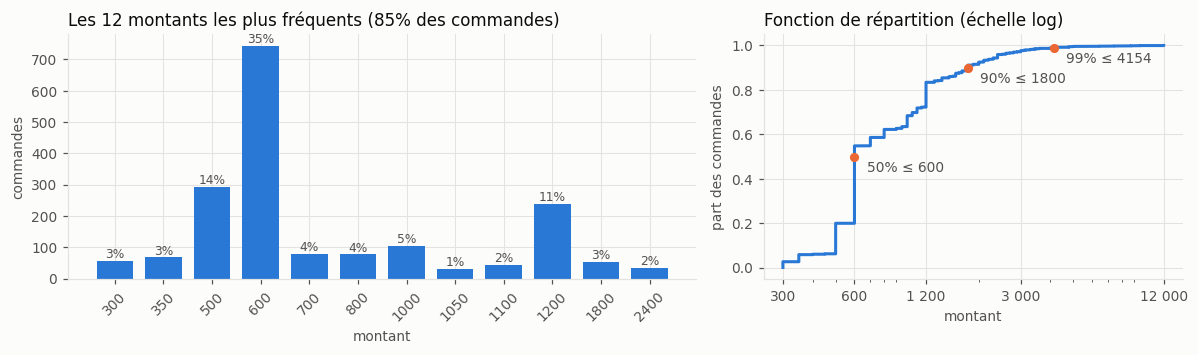

In [11]:
frequents = montant.value_counts()
haut = frequents.head(12).sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [3, 2]})
positions = np.arange(len(haut))
axes[0].bar(positions, haut.values, color=BLEU, width=0.75)
axes[0].set_xticks(positions, [f"{v:.0f}" for v in haut.index], rotation=45)
for x, v in zip(positions, haut.values):
    axes[0].annotate(f"{v / montant.size:.0%}", (x, v), xytext=(0, 2), textcoords="offset points", ha="center", color=TEXTE_2, fontsize=8)
axes[0].set(title=f"Les 12 montants les plus fréquents ({haut.sum() / montant.size:.0%} des commandes)", xlabel="montant", ylabel="commandes")

tri = np.sort(montant)
axes[1].step(tri, np.arange(1, tri.size + 1) / tri.size, where="post", color=BLEU, linewidth=2)
axes[1].set_xscale("log")
axes[1].set_xticks([300, 600, 1200, 3000, 12000], ["300", "600", "1 200", "3 000", "12 000"])
for q in [0.5, 0.9, 0.99]:
    v = montant.quantile(q)
    axes[1].plot([v], [q], "o", color=ORANGE, markersize=5)
    axes[1].annotate(f"{q:.0%} ≤ {v:.0f}", (v, q), xytext=(8, -10), textcoords="offset points", color=TEXTE_2)
axes[1].set(title="Fonction de répartition (échelle log)", xlabel="montant", ylabel="part des commandes")
fig.tight_layout()
plt.show()

**Le montant n'est pas une variable continue, c'est une somme de quelques prix.** 600 représente à lui seul 35 % des commandes : c'est le prix d'une grande bière. 1 200 (deux grandes bières) en représente 11 %, et 500, 14 %. Les 12 montants les plus fréquents couvrent 85 % des commandes, et tous les montants sont multiples de 50.

La distribution est très asymétrique à droite (asymétrie 4,6). La moyenne (976, IC 95 % [941 ; 1 011]) dépasse nettement la médiane (600). L'IC bootstrap de la médiane se réduit à [600 ; 600] : un tiers des commandes valent exactement ce montant. Le logarithme réduit l'asymétrie à 0,97, mais la normalité reste rejetée (D'Agostino p ≈ 6e-63, Shapiro-Wilk W = 0,90), car les valeurs sont regroupées en paliers.

Les 6,7 % de commandes au-delà de q3 + 1,5 IQR (2 100) ne sont pas des erreurs : ce sont des commandes de plusieurs articles, jusqu'à 12 Heineken pour 12 000. Elles sont gardées.

**Conséquence :** les comparaisons de montants utiliseront des tests de rang (Mann-Whitney, Kruskal-Wallis) et des médianes, pas des tests de moyennes sous hypothèse de normalité.

### 2.2 Quantités, lignes et articles par commande

In [12]:
def dispersion_poisson(x):
    """Test de surdispersion : sous Poisson, la somme des carrés des écarts divisée par la moyenne suit un khi2 à n-1 ddl."""
    x = np.asarray(x, dtype=float)
    indice = x.var(ddof=1) / x.mean()
    khi2 = ((x - x.mean()) ** 2).sum() / x.mean()
    return indice, stats.chi2.sf(khi2, x.size - 1)


comptages = {"quantité d'une ligne": donnees["quantite"], "lignes par commande": commandes["lignes"],
             "articles par commande": commandes["articles"]}
lignes_tab = []
for nom, serie in comptages.items():
    indice, p = dispersion_poisson(serie - 1)
    lignes_tab.append({"variable": nom, "moyenne": serie.mean(), "médiane": serie.median(), "maximum": serie.max(),
                       "part = 1": (serie == 1).mean(), "indice de dispersion (x - 1)": indice, "p surdispersion": p})
display(pd.DataFrame(lignes_tab).set_index("variable").round(3))
print("Quantités :", donnees["quantite"].value_counts().sort_index().to_dict())

,moyenne,médiane,maximum,part = 1,indice de dispersion (x - 1),p surdispersion
variable,,,,,,
quantité d'une ligne,1.377,1.0,25,0.767,3.054,0.0
lignes par commande,1.234,1.0,5,0.819,1.328,0.0
articles par commande,1.699,1.0,25,0.633,3.039,0.0


Quantités : {1: 2018, 2: 440, 3: 99, 4: 40, 5: 4, 6: 18, 7: 1, 8: 3, 9: 2, 10: 1, 12: 3, 20: 1, 25: 1}


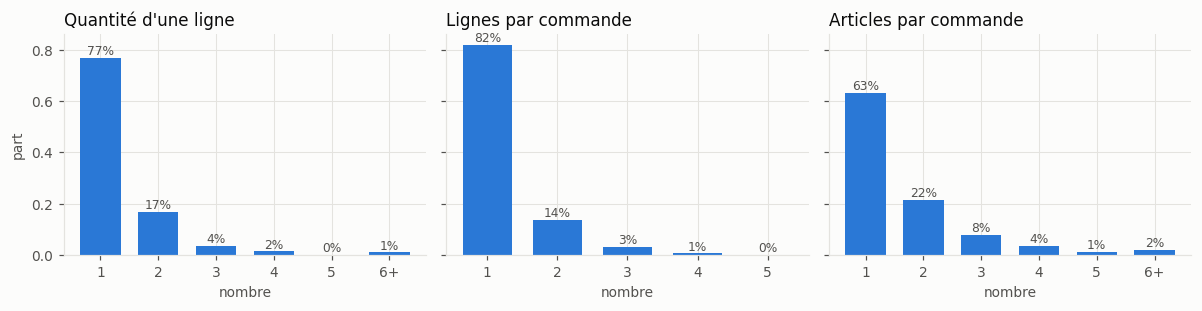

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9), sharey=True)
for ax, (nom, serie) in zip(axes, comptages.items()):
    parts = serie.clip(upper=6).value_counts(normalize=True).sort_index()
    ax.bar(parts.index, parts.values, color=BLEU, width=0.7)
    ax.set_xticks(parts.index, [str(i) if i < 6 else "6+" for i in parts.index])
    for x, v in parts.items():
        ax.annotate(f"{v:.0%}", (x, v), xytext=(0, 2), textcoords="offset points", ha="center", color=TEXTE_2, fontsize=8)
    ax.set(title=nom.capitalize(), xlabel="nombre")
axes[0].set_ylabel("part")
fig.tight_layout()
plt.show()

Les trois comptages sont dominés par la valeur 1 : 77 % des lignes portent un seul article, 82 % des commandes une seule ligne, et 63 % un seul article au total. Le test de dispersion rejette le modèle de Poisson pour les trois (p < 1e-15). Pour la quantité et le nombre d'articles, la variance de x - 1 vaut 3 fois sa moyenne : la plupart des clients prennent une bouteille, et quelques-uns prennent beaucoup plus. La moyenne est donc tirée par une minorité.

La quantité 6 apparaît 18 fois, contre 4 fois pour 5 et 1 fois pour 7. Ce pic à la demi-douzaine suggère un achat par lot.

### 2.3 Prix unitaires

In [14]:
prix = donnees["montant_unitaire"]
print(resumer(prix).round(1).to_dict())
print("Prix distincts :", prix.value_counts().sort_index().to_dict())

prix_par_produit = donnees.groupby("produit_net")["montant_unitaire"].agg(lignes="size", prix_distincts="nunique",
                                                                        minimum="min", maximum="max")
plusieurs = prix_par_produit[prix_par_produit["prix_distincts"] > 1].sort_values("lignes", ascending=False)
print(f"{len(plusieurs)} produits sur {len(prix_par_produit)} ont plusieurs prix ; ils couvrent "
      f"{plusieurs['lignes'].sum() / len(donnees):.1%} des lignes")
display(plusieurs)

{'effectif': 2631.0, 'moyenne': 584.6, 'écart-type': 167.6, 'minimum': 300.0, 'q1': 500.0, 'médiane': 600.0, 'q3': 600.0, 'maximum': 5000.0, 'asymétrie': 7.6, 'aplatissement': 184.0, 'au-delà de q3 + 1,5 IQR': 0.1}
Prix distincts : {300.0: 92, 350.0: 200, 400.0: 16, 450.0: 4, 500.0: 508, 550.0: 1, 600.0: 1449, 700.0: 119, 800.0: 117, 900.0: 4, 1000.0: 106, 1100.0: 9, 1300.0: 3, 1500.0: 2, 5000.0: 1}
27 produits sur 61 ont plusieurs prix ; ils couvrent 86.3% des lignes


,lignes,prix_distincts,minimum,maximum
produit_net,,,,
Flag 65cl (Grande),444,2,600.0,700.0
Kankpe 65cl (Grande),212,2,600.0,700.0
Doppel Munich 65cl (Noir) (Grande),207,2,600.0,700.0
Castel Beer 65cl (Grande),199,4,500.0,700.0
La Beninoise 65cl (Grande),148,2,600.0,700.0
Eku 33cl (Petite),131,2,600.0,700.0
Guinness 33cl (Petite),99,3,700.0,900.0
Beaufort 33cl (Petite),91,3,450.0,600.0
La Beninoise 33cl (Petite),90,2,350.0,400.0


Le prix unitaire ne prend que 15 valeurs, de 300 à 5 000. Le point important est ailleurs : **27 produits sur 61 ont plusieurs prix**, et ils couvrent 86,3 % des lignes. Un même produit est donc vendu à des prix différents selon les commandes. Cette variation est étudiée en section 3.1 avec le temps et la taille de la commande.

### 2.4 Produits et catégories

In [15]:
ventes = donnees.groupby("produit_net").agg(lignes=("n_commande", "size"), articles=("quantite", "sum"),
                                           chiffre=("sous_total", "sum"), categorie=("categorie", "first"))
ventes = ventes.sort_values("articles", ascending=False)


def gini(valeurs):
    x = np.sort(np.asarray(valeurs, dtype=float))
    n = x.size
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())


gini_ic = stats.bootstrap((ventes["articles"].to_numpy(),), gini, n_resamples=3000, method="percentile", batch=250, random_state=0).confidence_interval
parts = ventes["articles"] / ventes["articles"].sum()
print(f"Gini des articles vendus : {gini(ventes['articles']):.3f}, IC 95 % [{gini_ic.low:.3f} ; {gini_ic.high:.3f}]")
print(f"Indice de Herfindahl : {(parts ** 2).sum():.3f} (1/n = {1 / len(parts):.3f})")
for k in [1, 5, 10]:
    print(f"Top {k} : {parts.head(k).sum():.1%} des articles")
print(f"Produits vendus moins de 5 fois : {(ventes['articles'] < 5).sum()}")
print("Khi2 d'ajustement à une répartition uniforme :", stats.chisquare(ventes["articles"]))
display(ventes.head(10))

par_categorie = donnees.groupby("categorie").agg(lignes=("n_commande", "size"), articles=("quantite", "sum"),
                                               chiffre=("sous_total", "sum"), produits=("produit_net", "nunique"))
par_categorie = (par_categorie / par_categorie.sum()).round(3).assign(produits=par_categorie["produits"])
display(par_categorie.sort_values("articles", ascending=False))

Gini des articles vendus : 0.705, IC 95 % [0.625 ; 0.762]
Indice de Herfindahl : 0.064 (1/n = 0.016)
Top 1 : 16.1% des articles
Top 5 : 44.9% des articles
Top 10 : 69.5% des articles
Produits vendus moins de 5 fois : 18
Khi2 d'ajustement à une répartition uniforme : Power_divergenceResult(statistic=np.float64(10433.854816450454), pvalue=np.float64(0.0))


,lignes,articles,chiffre,categorie
produit_net,,,,
Flag 65cl (Grande),444,584,355100.0,bière
Eku 33cl (Petite),131,273,168300.0,bière
Castel Beer 65cl (Grande),199,269,153150.0,bière
Kankpe 65cl (Grande),212,266,160700.0,bière
Doppel Munich 65cl (Noir) (Grande),207,235,142400.0,bière
Kankpe 33cl (Petite),86,229,80450.0,bière
La Beninoise 33cl (Petite),90,197,69450.0,bière
Beaufort 33cl (Petite),91,179,91350.0,bière
La Beninoise 65cl (Grande),148,175,105100.0,bière


,lignes,articles,chiffre,produits
categorie,,,,
bière,0.741,0.791,0.791,24
soda,0.090,0.070,0.050,15
autre alcool,0.054,0.049,0.068,5
eau,0.060,0.047,0.048,7
énergisant,0.049,0.038,0.034,3
plat,0.006,0.005,0.008,7


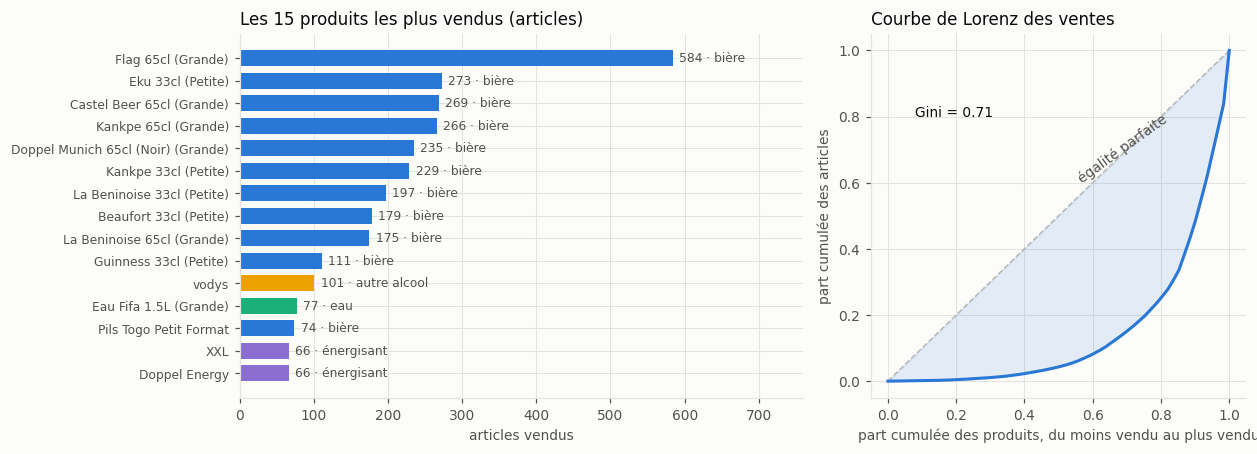

In [16]:
COULEUR_CATEGORIE = {"bière": BLEU, "soda": ORANGE, "eau": VERT, "autre alcool": JAUNE, "énergisant": "#8a6fd1", "plat": NEUTRE}
top = ventes.head(15).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [3, 2]})
axes[0].barh(top.index, top["articles"], color=[COULEUR_CATEGORIE[c] for c in top["categorie"]], height=0.7)
for y, (v, c) in enumerate(zip(top["articles"], top["categorie"])):
    axes[0].annotate(f"{v} · {c}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=TEXTE_2, fontsize=8)
axes[0].set(title="Les 15 produits les plus vendus (articles)", xlabel="articles vendus")
axes[0].set_xlim(0, top["articles"].max() * 1.3)
axes[0].tick_params(axis="y", labelsize=8)

cumul = np.concatenate([[0], np.cumsum(np.sort(ventes["articles"].to_numpy())) / ventes["articles"].sum()])
abscisse = np.linspace(0, 1, cumul.size)
axes[1].plot([0, 1], [0, 1], color=NEUTRE, linewidth=1, linestyle="--")
axes[1].plot(abscisse, cumul, color=BLEU, linewidth=2)
axes[1].fill_between(abscisse, cumul, abscisse, color=BLEU, alpha=0.12)
axes[1].annotate(f"Gini = {gini(ventes['articles']):.2f}", (0.08, 0.8), color=TEXTE)
axes[1].annotate("égalité parfaite", (0.55, 0.6), color=TEXTE_2, rotation=36)
axes[1].set(title="Courbe de Lorenz des ventes", xlabel="part cumulée des produits, du moins vendu au plus vendu",
            ylabel="part cumulée des articles")
fig.tight_layout()
plt.show()

**Les ventes sont très concentrées.** Le Gini des articles vendus vaut 0,71 (IC 95 % [0,63 ; 0,76]). Flag 65cl représente à elle seule 16,1 % des articles, les 5 premiers produits 44,9 % et les 10 premiers 69,5 %. À l'autre bout, 18 produits sont vendus moins de 5 fois. Le khi2 rejette évidemment une répartition uniforme : c'est la courbe de Lorenz qui montre l'ampleur de l'écart.

Les 10 produits les plus vendus sont tous des bières. La bière pèse 79 % des articles et du chiffre d'affaires, avec 24 produits. Les sodas ont 15 produits mais seulement 5 % du chiffre. Les plats sont marginaux (0,6 % des lignes).

**Conséquence :** une analyse par produit n'est fiable que pour une quinzaine de produits. Au-delà, il faut raisonner par catégorie ou regrouper les produits rares.

### 2.5 Heure de commande

À partir d'ici, les analyses de temps portent sur les commandes de la période d'étude (9 au 26 octobre).

In [17]:
periode_cmd = commandes[commandes["dans_periode"]].copy()
heures = periode_cmd["date"].dt.hour
par_heure = heures.value_counts().reindex(range(24), fill_value=0)
print(f"{len(periode_cmd)} commandes dans la période d'étude")
print("Khi2 d'ajustement à une répartition uniforme sur 24 h :", stats.chisquare(par_heure))

# Statistique circulaire : l'heure 23 est voisine de l'heure 0
angles = periode_cmd["heure"].to_numpy() * 2 * np.pi / 24
n = angles.size
c, s = np.cos(angles).sum(), np.sin(angles).sum()
longueur = np.hypot(c, s) / n
heure_moyenne = (np.arctan2(s, c) % (2 * np.pi)) * 24 / (2 * np.pi)
rn = n * longueur
p_rayleigh = np.exp(np.sqrt(1 + 4 * n + 4 * (n ** 2 - rn ** 2)) - (1 + 2 * n))
print(f"Heure moyenne circulaire : {int(heure_moyenne)} h {int(heure_moyenne % 1 * 60):02d}")
print(f"Longueur moyenne du vecteur résultant : {longueur:.3f} | test de Rayleigh p = {p_rayleigh:.2e}")
print("Part par tranche :", periode_cmd["tranche"].value_counts(normalize=True).reindex(TRANCHES).round(3).to_dict())
print(f"Commandes entre 18 h et 2 h : {heures.isin([18, 19, 20, 21, 22, 23, 0, 1]).mean():.1%}")

2116 commandes dans la période d'étude
Khi2 d'ajustement à une répartition uniforme sur 24 h : Power_divergenceResult(statistic=np.float64(2553.996219281663), pvalue=np.float64(0.0))
Heure moyenne circulaire : 21 h 11
Longueur moyenne du vecteur résultant : 0.679 | test de Rayleigh p = 0.00e+00
Part par tranche : {'journée': 0.163, 'début de soirée': 0.321, 'soirée': 0.35, 'nuit': 0.166}
Commandes entre 18 h et 2 h : 79.6%


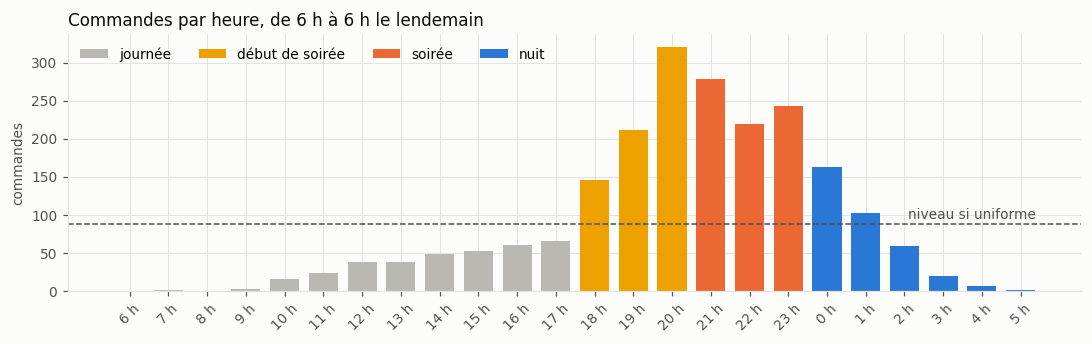

In [18]:
ordre_heures = list(range(6, 24)) + list(range(0, 6))
valeurs = par_heure.reindex(ordre_heures)
couleur_tranche = {"journée": NEUTRE, "début de soirée": JAUNE, "soirée": ORANGE, "nuit": BLEU}
tranche_heure = lambda h: "nuit" if h < 6 else "journée" if h < 18 else "début de soirée" if h < 21 else "soirée"

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(24), valeurs.values, color=[couleur_tranche[tranche_heure(h)] for h in ordre_heures], width=0.75)
ax.set_xticks(range(24), [f"{h} h" for h in ordre_heures], rotation=45)
ax.axhline(n / 24, color=TEXTE_2, linewidth=1, linestyle="--")
ax.annotate("niveau si uniforme", (23.4, n / 24), xytext=(0, 3), textcoords="offset points", ha="right", color=TEXTE_2)
for tranche, couleur in couleur_tranche.items():
    ax.bar([0], [0], color=couleur, label=tranche)
ax.legend(frameon=False, ncol=4, loc="upper left")
ax.set(title="Commandes par heure, de 6 h à 6 h le lendemain", ylabel="commandes")
fig.tight_layout()
plt.show()

L'activité est nocturne. 79,6 % des commandes tombent entre 18 h et 2 h, avec un pic à 20 h (321 commandes). Après minuit, les commandes restent nombreuses jusqu'à 2 h, puis s'arrêtent presque. Avant 10 h, il n'y a presque rien.

Deux tests le confirment. Le khi2 rejette une répartition uniforme sur 24 h. Le test de Rayleigh, qui traite l'heure comme un angle pour que 23 h et 0 h soient voisins, rejette l'absence de direction préférée (p ≈ 0). L'heure moyenne circulaire est **21 h 11**, avec une concentration forte (R = 0,68 sur une échelle de 0 à 1).

Les tranches retenues en section 1.5 suivent ces ruptures : journée calme (16,3 %), montée de 18 h à 21 h (32,1 %), plateau de 21 h à minuit (35,0 %), fin de nuit (16,6 %).

### 2.6 Jours et évolution sur la période

In [19]:
soirees = periode_cmd.groupby("soiree").agg(commandes=("montant", "size"), chiffre=("montant", "sum"))
soirees["jour"] = pd.Categorical(soirees.index.dayofweek.map(dict(enumerate(JOURS))), categories=JOURS, ordered=True)

par_jour = soirees.groupby("jour", observed=False).agg(soirees=("commandes", "size"), commandes=("commandes", "sum"),
                                                      moyenne=("commandes", "mean"), minimum=("commandes", "min"),
                                                      maximum=("commandes", "max"))
attendu = par_jour["soirees"] / par_jour["soirees"].sum() * par_jour["commandes"].sum()
par_jour["attendu si égal"] = attendu.round(1)
display(par_jour.round(1))
print("Khi2 d'ajustement (attendu proportionnel au nombre de soirées) :",
      stats.chisquare(par_jour["commandes"], attendu))
print("Kruskal-Wallis sur les comptages par soirée :", stats.kruskal(*[g["commandes"] for _, g in soirees.groupby("jour", observed=True)]))

indice, p = dispersion_poisson(soirees["commandes"])
print(f"Commandes par soirée : moyenne {soirees['commandes'].mean():.1f}, indice de dispersion {indice:.1f}, p = {p:.1e}")
tendance = stats.spearmanr(np.arange(len(soirees)), soirees["commandes"])
print(f"Tendance sur la période (Spearman) : rho = {tendance.statistic:.3f}, p = {tendance.pvalue:.3f}")

,soirees,commandes,moyenne,minimum,maximum,attendu si égal
jour,,,,,,
lundi,3,218,72.7,53,112,352.7
mardi,2,227,113.5,100,127,235.1
mercredi,2,255,127.5,112,143,235.1
jeudi,2,180,90.0,79,101,235.1
vendredi,3,298,99.3,64,128,352.7
samedi,3,445,148.3,117,179,352.7
dimanche,3,493,164.3,120,210,352.7


Khi2 d'ajustement (attendu proportionnel au nombre de soirées) : Power_divergenceResult(statistic=np.float64(154.79300567107754), pvalue=np.float64(7.494798150480789e-31))
Kruskal-Wallis sur les comptages par soirée : KruskalResult(statistic=np.float64(10.778093760772148), pvalue=np.float64(0.09548164213213792))
Commandes par soirée : moyenne 117.6, indice de dispersion 14.9, p = 6.1e-44
Tendance sur la période (Spearman) : rho = 0.007, p = 0.977


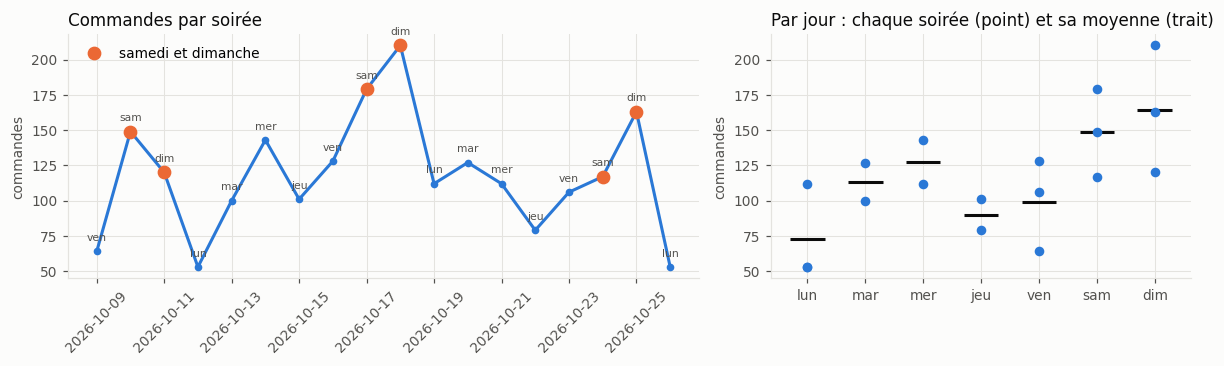

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [3, 2]})
axes[0].plot(soirees.index, soirees["commandes"], color=BLEU, linewidth=2, marker="o", markersize=4)
fin = soirees[soirees["jour"].isin(["samedi", "dimanche"])]
axes[0].plot(fin.index, fin["commandes"], "o", color=ORANGE, markersize=8, label="samedi et dimanche")
for jour_, ligne in soirees.iterrows():
    axes[0].annotate(ligne["jour"][:3], (jour_, ligne["commandes"]), xytext=(0, 7), textcoords="offset points",
                     ha="center", fontsize=7, color=TEXTE_2)
axes[0].legend(frameon=False, loc="upper left")
axes[0].set(title="Commandes par soirée", ylabel="commandes")
axes[0].tick_params(axis="x", rotation=45)

rang = np.arange(len(JOURS))
for i, jour_ in enumerate(JOURS):
    points = soirees.loc[soirees["jour"] == jour_, "commandes"]
    axes[1].scatter(np.full(len(points), i), points, color=BLEU, s=28, zorder=3)
    axes[1].hlines(points.mean(), i - 0.3, i + 0.3, color=TEXTE, linewidth=2)
axes[1].set_xticks(rang, [j[:3] for j in JOURS])
axes[1].set(title="Par jour : chaque soirée (point) et sa moyenne (trait)", ylabel="commandes")
fig.tight_layout()
plt.show()

**Les deux tests ne disent pas la même chose, et c'est le second qu'il faut croire.** Le khi2 compare 2 116 commandes et rejette très nettement l'égalité entre jours (p ≈ 7e-31). Mais il suppose les commandes indépendantes, alors qu'elles arrivent par soirées entières. Or le nombre de commandes varie énormément d'une soirée à l'autre : de 53 à 210, avec un indice de dispersion de 14,9 au lieu de 1 sous Poisson. La vraie unité est donc la soirée, et il n'y en a que 18. Sur ces 18 soirées, Kruskal-Wallis ne rejette pas l'égalité des jours (p = 0,095).

Le graphique montre pourtant un motif : les samedis et dimanches sont en haut, les lundis en bas. Je teste ce contraste. Il est suggéré par le graphique et non prévu à l'avance, donc sa p-value est optimiste.

Aucune tendance sur la période (Spearman rho = 0,007, p = 0,98) : l'activité ne monte ni ne baisse en trois semaines.

In [21]:
fin_semaine = soirees["jour"].isin(["samedi", "dimanche"])
a, b = soirees.loc[fin_semaine, "commandes"], soirees.loc[~fin_semaine, "commandes"]
test = stats.mannwhitneyu(a, b, alternative="two-sided", method="exact")
print(f"Samedi et dimanche : {len(a)} soirées, médiane {a.median():.0f} | autres jours : {len(b)} soirées, médiane {b.median():.0f}")
print(f"Mann-Whitney exact : U = {test.statistic:.0f}, p = {test.pvalue:.4f}, corrélation bisériale de rang = {2 * test.statistic / (len(a) * len(b)) - 1:.2f}")
print("Rapport des moyennes :", round(a.mean() / b.mean(), 2))

Samedi et dimanche : 6 soirées, médiane 156 | autres jours : 12 soirées, médiane 104
Mann-Whitney exact : U = 66, p = 0.0032, corrélation bisériale de rang = 0.83
Rapport des moyennes : 1.59


Les soirées du samedi et du dimanche comptent en moyenne 1,59 fois plus de commandes que les autres (médianes 156 contre 104). Le test exact de Mann-Whitney sur les 18 soirées donne p = 0,003, avec un effet très fort (corrélation bisériale 0,83). Même en tenant compte du fait que ce contraste a été choisi après avoir vu le graphique, l'écart est net. **La variable utile n'est pas le jour, mais la fin de semaine.** Avec deux ou trois soirées par jour, les différences entre jours de semaine ne peuvent pas être établies.

## 3. Analyse bivariée

Chaque couple est testé avec l'outil adapté à ses types. La p-value dit si un lien est probable ; la taille d'effet dit s'il compte. Les comparaisons de montants utilisent des tests de rang (section 2.1).

### 3.1 Prix et moment de la commande

La section 2.3 a montré que 27 produits ont plusieurs prix. Pour chaque produit, le **prix de référence** est son prix le plus fréquent. Chaque ligne est alors au tarif normal, majoré ou réduit.

In [22]:
reference = donnees.groupby("produit_net")["montant_unitaire"].agg(lambda s: s.mode().iloc[0])
donnees["ecart_prix"] = donnees["montant_unitaire"] - donnees["produit_net"].map(reference)
donnees["tarif"] = np.select([donnees["ecart_prix"] > 0, donnees["ecart_prix"] < 0], ["majoré", "réduit"], "normal")
print("Écarts au prix de référence :", donnees["ecart_prix"].value_counts().sort_index().to_dict())

lignes_periode = donnees[donnees["soiree"].between("2026-10-09", "2026-10-26")].copy()
lignes_periode["heure_entiere"] = lignes_periode["date"].dt.hour
display(pd.crosstab(lignes_periode["jour"], lignes_periode["tarif"], margins=True))

Écarts au prix de référence : {-200.0: 12, -100.0: 121, -50.0: 5, 0.0: 2333, 50.0: 12, 100.0: 148}


tarif,majoré,normal,réduit,All
jour,,,,
lundi,0,229,25,254
mardi,0,270,12,282
mercredi,0,280,26,306
jeudi,0,224,15,239
vendredi,0,355,21,376
samedi,157,399,15,571
dimanche,2,547,24,573
All,159,2304,138,2601


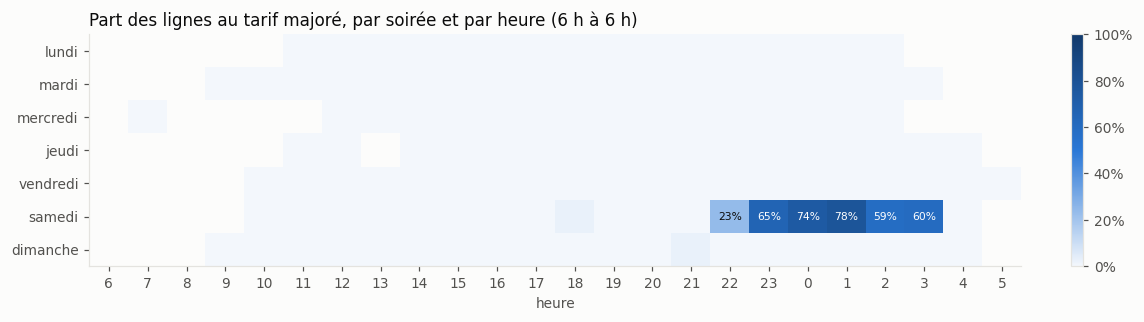

In [23]:
majore = lignes_periode.assign(majore=lignes_periode["tarif"] == "majoré")
carte = majore.pivot_table(index="jour", columns="heure_entiere", values="majore", aggfunc="mean", observed=False)
carte = carte.reindex(columns=ordre_heures)

fig, ax = plt.subplots(figsize=(10.5, 3))
image = ax.imshow(carte.to_numpy(dtype=float), cmap=RAMPE, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(24), [f"{h}" for h in ordre_heures])
ax.set_yticks(range(7), JOURS)
ax.grid(False)
for (i, j), v in np.ndenumerate(carte.to_numpy(dtype=float)):
    if v >= 0.05:
        ax.annotate(f"{v:.0%}", (j, i), ha="center", va="center", fontsize=7, color="white" if v > 0.5 else TEXTE)
ax.set(title="Part des lignes au tarif majoré, par soirée et par heure (6 h à 6 h)", xlabel="heure")
fig.colorbar(image, ax=ax, fraction=0.02, format=lambda x, _: f"{x:.0%}")
fig.tight_layout()
plt.show()

In [24]:
heure_ligne = lignes_periode["date"].dt.hour
lignes_periode["samedi_nuit"] = (lignes_periode["jour"] == "samedi") & ((heure_ligne >= 22) | (heure_ligne < 6))
table = pd.crosstab(lignes_periode["samedi_nuit"], lignes_periode["tarif"] == "majoré").reindex(index=[True, False], columns=[True, False])
table.index, table.columns = ["samedi 22 h - 6 h", "reste du temps"], ["majoré", "non majoré"]
display(table.assign(part_majoree=table["majoré"] / table.sum(axis=1)).round(3))
rapport, p = stats.fisher_exact(table.to_numpy())
print(f"Fisher : odds ratio = {rapport:.0f}, p = {p:.1e}")
print("Lignes majorées hors fenêtre :")
display(lignes_periode.loc[(lignes_periode["tarif"] == "majoré") & ~lignes_periode["samedi_nuit"],
                           ["n_commande", "date", "produit", "montant_unitaire"]])

,majoré,non majoré,part_majoree
samedi 22 h - 6 h,156,111,0.584
reste du temps,3,2331,0.001


Fisher : odds ratio = 1092, p = 2.2e-172
Lignes majorées hors fenêtre :


,n_commande,date,produit,montant_unitaire
362,CW1405872,2026-10-25 21:06:49.521000+01:00,Hagbè 50cl (Grande),600.0
458,CW1892000,2026-10-10 18:23:15.547000+01:00,Hagbè 50cl (Grande),600.0
1975,CW7730323,2026-10-25 21:05:12.018000+01:00,Hagbè 50cl (Grande),600.0


Dans la fenêtre, une ligne sur trois seulement est majorée. Je regarde quelles lignes y échappent : selon la soirée, selon la catégorie, et selon le libellé du produit.

In [25]:
fenetre = lignes_periode[lignes_periode["samedi_nuit"]].copy()
fenetre["majore"] = fenetre["tarif"] == "majoré"


def part_et_test(variable):
    tableau = pd.crosstab(fenetre[variable], fenetre["majore"])
    khi2, p, ddl, attendus = stats.chi2_contingency(tableau)
    v = np.sqrt(khi2 / (tableau.to_numpy().sum() * (min(tableau.shape) - 1)))
    resume = tableau.assign(lignes=tableau.sum(axis=1), part_majoree=tableau[True] / tableau.sum(axis=1))
    return resume[["lignes", "part_majoree"]].round(3), p, v, (attendus < 5).mean()


for variable in ["soiree", "categorie"]:
    resume, p, v, rares = part_et_test(variable)
    display(resume)
    print(f"{variable} : khi2 p = {p:.1e}, V de Cramér = {v:.2f}, attendus < 5 : {rares:.0%}")

fenetre["minute_debut"] = fenetre["date"].dt.hour * 60 + fenetre["date"].dt.minute
debut = fenetre[fenetre["majore"]].groupby("soiree")["date"].min()
print("Première ligne majorée de chaque samedi :", debut.dt.strftime("%d/%m %H:%M").to_dict())

bieres = fenetre[fenetre["categorie"] == "bière"]
detail = bieres.groupby("produit")["majore"].agg(lignes="size", majorees="sum")
display(detail[detail["lignes"] >= 4].assign(part=lambda t: (t["majorees"] / t["lignes"]).round(2)).sort_values("part"))

majore,lignes,part_majoree
soiree,,
2026-10-10,122,0.664
2026-10-17,87,0.655
2026-10-24,58,0.310


soiree : khi2 p = 1.1e-05, V de Cramér = 0.29, attendus < 5 : 0%


majore,lignes,part_majoree
categorie,,
autre alcool,23,0.609
bière,185,0.595
eau,18,0.611
soda,18,0.333
énergisant,23,0.652


categorie : khi2 p = 2.6e-01, V de Cramér = 0.14, attendus < 5 : 0%
Première ligne majorée de chaque samedi : {Timestamp('2026-10-10 00:00:00'): '10/10 22:26', Timestamp('2026-10-17 00:00:00'): '17/10 22:01', Timestamp('2026-10-24 00:00:00'): '24/10 23:00'}


,lignes,majorees,part
produit,,,
Kanpke 65cl (Grande),4,0,0.00
La Beninoise 65cl (Grande),7,1,0.14
Guinness 33cl (Petite),13,4,0.31
Castel Beer 65cl (Grande),16,7,0.44
Awoyo 65cl (Grande),4,2,0.50
Kankpe 33cl (Petite),6,3,0.50
Doppel Munich 65cl (Noir) (Grande),19,12,0.63
Beaufort 33cl (Petite),17,11,0.65
Flag 65cl (Grande),43,31,0.72


In [26]:
deux_fiches = fenetre[fenetre["produit"].isin(["Kankpe 65cl (Grande)", "Kanpke 65cl (Grande)"])]
display(pd.crosstab(deux_fiches["produit"], deux_fiches["majore"]))
print("Fisher, deux fiches de la Kankpe 65cl dans la fenêtre :", stats.fisher_exact(pd.crosstab(deux_fiches["produit"], deux_fiches["majore"]).to_numpy()))

majore,False,True
produit,,
Kankpe 65cl (Grande),4,11
Kanpke 65cl (Grande),4,0


Fisher, deux fiches de la Kankpe 65cl dans la fenêtre : SignificanceResult(statistic=np.float64(0.0), pvalue=np.float64(0.018059855521155826))


**La majoration est une règle tarifaire nocturne du samedi.** 156 des 159 lignes majorées tombent le samedi entre 22 h et 6 h. Dans cette fenêtre, 58,4 % des lignes sont majorées, contre 0,1 % le reste du temps (Fisher : odds ratio ≈ 1 092, p ≈ 2e-172). La hausse est presque toujours de +100, et de +50 pour quelques petits formats. Le seul produit majoré en dehors est `Hagbè 50cl` (3 lignes à 600 au lieu de 500) : c'est plutôt un changement de prix de ce produit qu'une majoration.

Dans la fenêtre, la majoration ne dépend pas de la catégorie (khi2 p = 0,26, V = 0,14) : bière, eau, énergisant et autres alcools sont majorés dans les mêmes proportions. Elle dépend de la soirée (p = 1e-05, V = 0,29) : 66 % des lignes le 10 et le 17, mais 31 % le 24, où la première ligne majorée arrive à 23 h au lieu de 22 h. **L'heure de début n'est donc pas fixe**, ce qui suggère une bascule manuelle plutôt qu'une règle automatique.

Elle dépend aussi de la fiche du produit. La fiche `Kanpke 65cl` n'est jamais majorée (0 sur 4) alors que `Kankpe 65cl` l'est 11 fois sur 15 (Fisher p = 0,018, sur de petits effectifs). Cela confirme la section 1.4 : ce sont deux fiches du même produit, mais elles ne suivent pas la même règle de prix.

**Conséquence :** le prix unitaire et le montant d'une commande dépendent du moment de la commande. Toute comparaison de montants entre moments doit séparer l'effet prix (majoration) de l'effet quantité (section 4.1).

### 3.2 Prix réduits et taille de la commande

In [27]:
reduits = lignes_periode[lignes_periode["tarif"] == "réduit"]
display(reduits.groupby("produit_net").agg(lignes=("tarif", "size"), ecart=("ecart_prix", lambda s: sorted(s.unique())),
                                           premiere_soiree=("soiree", "min"), derniere_soiree=("soiree", "max")))

produits_reduits = reduits.groupby("produit_net").size()
produits_reduits = produits_reduits[produits_reduits >= 10].index
debut_reduction = reduits.groupby("produit_net")["soiree"].min()
concernees = lignes_periode[lignes_periode["produit_net"].isin(produits_reduits)].copy()
concernees = concernees[concernees["soiree"] >= concernees["produit_net"].map(debut_reduction)]
concernees["commande_simple"] = concernees["n_commande"].map(commandes["lignes"]) == 1

table_reduit = pd.crosstab(concernees["commande_simple"], concernees["tarif"] == "réduit").reindex(index=[True, False], columns=[True, False])
table_reduit.index, table_reduit.columns = ["commande d'un seul produit", "commande de plusieurs produits"], ["réduit", "non réduit"]
display(table_reduit.assign(part_reduite=table_reduit["réduit"] / table_reduit.sum(axis=1)).round(3))
print("Fisher :", stats.fisher_exact(table_reduit.to_numpy()))

par_produit = {}
for produit, g in concernees.groupby("produit_net"):
    t = pd.crosstab(g["commande_simple"], g["tarif"] == "réduit").reindex(index=[True, False], columns=[True, False], fill_value=0)
    par_produit[produit] = {"réduit (simple)": t.loc[True, True] / t.loc[True].sum(), "réduit (multiple)": t.loc[False, True] / max(t.loc[False].sum(), 1),
                            "lignes multiples": t.loc[False].sum(), "p Fisher": stats.fisher_exact(t.to_numpy())[1]}
display(pd.DataFrame(par_produit).T.round(3))

,lignes,ecart,premiere_soiree,derniere_soiree
produit_net,,,,
Beaufort 33cl (Petite),1,[-50.0],2026-10-25,2026-10-25
Castel Beer 65cl (Grande),74,"[-100.0, -50.0]",2026-10-12,2026-10-26
Eau Fifa 1.5L (Grande),24,[-100.0],2026-10-14,2026-10-25
Guinness 33cl (Petite),24,[-100.0],2026-10-14,2026-10-26
tequila,3,[-50.0],2026-10-14,2026-10-21
vodys,12,[-200.0],2026-10-21,2026-10-26


,réduit,non réduit,part_reduite
commande d'un seul produit,131,96,0.577
commande de plusieurs produits,3,103,0.028


Fisher : SignificanceResult(statistic=np.float64(46.85069444444444), pvalue=np.float64(1.8865968417239045e-25))


,réduit (simple),réduit (multiple),lignes multiples,p Fisher
Castel Beer 65cl (Grande),0.559,0.054,56.0,0.0
Eau Fifa 1.5L (Grande),0.667,0.000,17.0,0.0
Guinness 33cl (Petite),0.533,0.000,21.0,0.0
vodys,0.632,0.000,12.0,0.0


Les prix réduits apparaissent à partir du 12 au 14 octobre, sur quatre produits : Castel 65cl (-100), Eau Fifa 1,5L (-100), Guinness 33cl (-100) et vodys (-200). Après le début de la réduction, le tarif réduit et le tarif normal coexistent les mêmes soirs.

**Ce qui les sépare, c'est la taille de la commande.** Quand le produit est commandé seul, 57,7 % des lignes sont au tarif réduit. Quand il est commandé avec d'autres produits, seulement 2,8 % (Fisher : odds ratio ≈ 47, p ≈ 2e-25). Le résultat se retrouve pour chacun des quatre produits pris séparément.

Le fichier ne dit pas pourquoi. Une hypothèse est une offre réservée à un canal ou à un mode de commande à produit unique. **Conséquence :** le prix d'une ligne dépend aussi de la composition de la commande, et pas seulement du produit et du moment.

### 3.3 Montant de la commande selon le moment

In [28]:
def rang_biseriale(a, b):
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    return u.pvalue, 2 * u.statistic / (len(a) * len(b)) - 1


def comparer_groupes(table, valeur, groupe):
    groupes = [g[valeur].to_numpy() for _, g in table.groupby(groupe, observed=True)]
    h, p = stats.kruskal(*groupes)
    n = sum(len(g) for g in groupes)
    epsilon2 = (h - len(groupes) + 1) / (n - len(groupes))
    return h, p, epsilon2


periode_cmd["fin_de_semaine"] = periode_cmd["jour"].isin(["samedi", "dimanche"])
periode_cmd["samedi_nuit"] = (periode_cmd["jour"] == "samedi") & ((periode_cmd["date"].dt.hour >= 22) | (periode_cmd["date"].dt.hour < 6))

resume_tranche = periode_cmd.groupby("tranche", observed=True).agg(
    commandes=("montant", "size"), mediane=("montant", "median"), moyenne=("montant", "mean"),
    articles_moyens=("articles", "mean"), plusieurs_articles=("articles", lambda s: (s > 1).mean()),
    prix_moyen_median=("prix_moyen", "median"))
display(resume_tranche.round(2))
for valeur in ["montant", "articles", "prix_moyen"]:
    h, p, e2 = comparer_groupes(periode_cmd, valeur, "tranche")
    print(f"Kruskal-Wallis {valeur} ~ tranche : H = {h:.1f}, p = {p:.1e}, epsilon² = {e2:.3f}")

paires = []
for a, b in [(a, b) for i, a in enumerate(TRANCHES) for b in TRANCHES[i + 1:]]:
    p, r = rang_biseriale(periode_cmd.loc[periode_cmd["tranche"] == a, "montant"], periode_cmd.loc[periode_cmd["tranche"] == b, "montant"])
    paires.append({"paire": f"{a} / {b}", "p": p, "bisériale": r})
paires = pd.DataFrame(paires)
paires["p_holm"] = multipletests(paires["p"], method="holm")[1]
display(paires.round(4))

print()
resume_fin = periode_cmd.groupby("fin_de_semaine").agg(commandes=("montant", "size"), mediane=("montant", "median"),
                                                       moyenne=("montant", "mean"), articles_moyens=("articles", "mean"))
display(resume_fin.round(1))
for valeur in ["montant", "articles"]:
    p, r = rang_biseriale(periode_cmd.loc[periode_cmd["fin_de_semaine"], valeur], periode_cmd.loc[~periode_cmd["fin_de_semaine"], valeur])
    print(f"Mann-Whitney {valeur} ~ fin de semaine : p = {p:.3f}, bisériale = {r:.3f}")

,commandes,mediane,moyenne,articles_moyens,plusieurs_articles,prix_moyen_median
tranche,,,,,,
journée,344,600.0,867.01,1.56,0.31,600.0
début de soirée,679,600.0,961.19,1.70,0.37,600.0
soirée,741,600.0,980.16,1.71,0.38,600.0
nuit,352,700.0,1050.28,1.72,0.38,600.0


Kruskal-Wallis montant ~ tranche : H = 21.8, p = 7.3e-05, epsilon² = 0.009
Kruskal-Wallis articles ~ tranche : H = 7.6, p = 5.6e-02, epsilon² = 0.002
Kruskal-Wallis prix_moyen ~ tranche : H = 34.9, p = 1.3e-07, epsilon² = 0.015


,paire,p,bisériale,p_holm
0,journée / début de soirée,0.0137,-0.0915,0.0549
1,journée / soirée,0.0001,-0.1461,0.0003
2,journée / nuit,0.0000,-0.1799,0.0002
3,début de soirée / soirée,0.0960,-0.0497,0.1919
4,début de soirée / nuit,0.0223,-0.0849,0.0670
5,soirée / nuit,0.3073,-0.0374,0.3073


,commandes,mediane,moyenne,articles_moyens
fin_de_semaine,,,,
False,1178,600.0,947.5,1.7
True,938,600.0,992.3,1.7


Mann-Whitney montant ~ fin de semaine : p = 0.122, bisériale = 0.038
Mann-Whitney articles ~ fin de semaine : p = 0.543, bisériale = 0.013


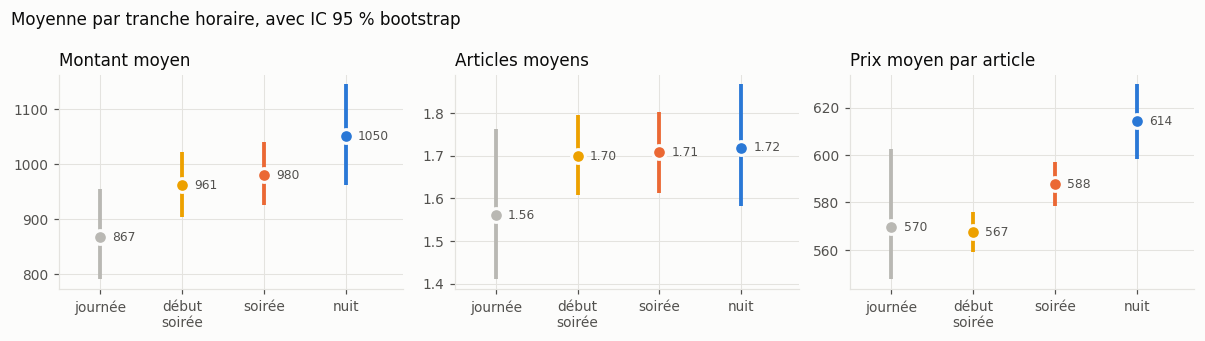

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1))
for ax, valeur, titre, fmt in [(axes[0], "montant", "Montant moyen", "{:.0f}"), (axes[1], "articles", "Articles moyens", "{:.2f}"),
                               (axes[2], "prix_moyen", "Prix moyen par article", "{:.0f}")]:
    for i, tranche in enumerate(TRANCHES):
        serie = periode_cmd.loc[periode_cmd["tranche"] == tranche, valeur].to_numpy()
        ic = stats.bootstrap((serie,), np.mean, n_resamples=3000, method="percentile", batch=250, random_state=0).confidence_interval
        ax.vlines(i, ic.low, ic.high, color=couleur_tranche[tranche], linewidth=2.5)
        ax.plot(i, serie.mean(), "o", color=couleur_tranche[tranche], markersize=9, markeredgecolor=FOND, markeredgewidth=2)
        ax.annotate(fmt.format(serie.mean()), (i, serie.mean()), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=TEXTE_2)
    ax.set_xticks(range(4), ["journée", "début\nsoirée", "soirée", "nuit"])
    ax.set_xlim(-0.5, 3.7)
    ax.set_title(titre)
fig.suptitle("Moyenne par tranche horaire, avec IC 95 % bootstrap", x=0.01, ha="left", fontsize=11, color=TEXTE)
fig.tight_layout()
plt.show()

**Le montant augmente au fil de la soirée, mais l'effet est faible.** Le montant moyen passe de 867 en journée à 1 050 la nuit, et la médiane de 600 à 700. Kruskal-Wallis rejette l'égalité (p = 7e-05), mais l'epsilon² n'est que de 0,009 : la tranche horaire explique moins de 1 % de la variation des rangs. Après correction de Holm, seule la journée se distingue clairement de la soirée et de la nuit (bisériales -0,15 et -0,18). Les tranches du soir ne diffèrent pas entre elles.

**Le graphique montre d'où vient cet écart.** Le nombre d'articles est presque stable (p = 0,056). C'est le prix moyen par article qui monte (p = 1e-07), surtout la nuit (614 contre 567 à 588). Deux explications sont possibles : la majoration du samedi soir, ou des produits plus chers commandés la nuit. La section 4.1 les sépare.

**La fin de semaine n'agrandit pas le panier** (montant p = 0,12, articles p = 0,54, bisériales < 0,04). Le samedi et le dimanche, il y a plus de commandes (section 2.6), mais pas de plus grosses commandes.

### 3.4 Catégorie et moment de la commande

L'unité est la commande, avec sa catégorie dominante. Les 7 commandes dominées par un plat sont exclues du test, car leurs effectifs attendus sont sous 5.

In [30]:
def v_cramer(tableau):
    """V de Cramér avec correction de biais (Bergsma), et part des effectifs attendus sous 5."""
    khi2, p, ddl, attendus = stats.chi2_contingency(tableau, correction=False)
    n = tableau.to_numpy().sum()
    r, k = tableau.shape
    phi2 = max(0, khi2 / n - (r - 1) * (k - 1) / (n - 1))
    r_corr, k_corr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return khi2, p, ddl, np.sqrt(phi2 / min(r_corr - 1, k_corr - 1)), (attendus < 5).mean()


ORDRE_CATEGORIES = ["bière", "soda", "eau", "autre alcool", "énergisant"]
avec_categorie = periode_cmd[periode_cmd["categorie_dominante"].isin(ORDRE_CATEGORIES)]
print("Commandes dominées par un plat dans la période :", (periode_cmd["categorie_dominante"] == "plat").sum())

for variable in ["tranche", "fin_de_semaine"]:
    tableau = pd.crosstab(avec_categorie["categorie_dominante"], avec_categorie[variable]).reindex(ORDRE_CATEGORIES)
    khi2, p, ddl, v, rares = v_cramer(tableau)
    print(f"catégorie x {variable} : khi2 = {khi2:.1f}, ddl = {ddl}, p = {p:.1e}, V = {v:.3f}, attendus < 5 : {rares:.0%}")

tableau = pd.crosstab(avec_categorie["categorie_dominante"], avec_categorie["tranche"]).reindex(ORDRE_CATEGORIES)
display((tableau / tableau.sum()).round(3))
_, _, _, attendus = stats.chi2_contingency(tableau)
n = tableau.to_numpy().sum()
lignes_tot, colonnes_tot = tableau.sum(axis=1).to_numpy()[:, None] / n, tableau.sum(axis=0).to_numpy()[None, :] / n
residus = (tableau - attendus) / np.sqrt(attendus * (1 - lignes_tot) * (1 - colonnes_tot))

Commandes dominées par un plat dans la période : 7
catégorie x tranche : khi2 = 61.9, ddl = 12, p = 1.0e-08, V = 0.089, attendus < 5 : 0%
catégorie x fin_de_semaine : khi2 = 15.8, ddl = 4, p = 3.4e-03, V = 0.075, attendus < 5 : 0%


tranche,journée,début de soirée,soirée,nuit
categorie_dominante,,,,
bière,0.753,0.785,0.786,0.716
soda,0.109,0.096,0.064,0.051
eau,0.082,0.069,0.047,0.065
autre alcool,0.038,0.031,0.057,0.094
énergisant,0.018,0.019,0.046,0.074


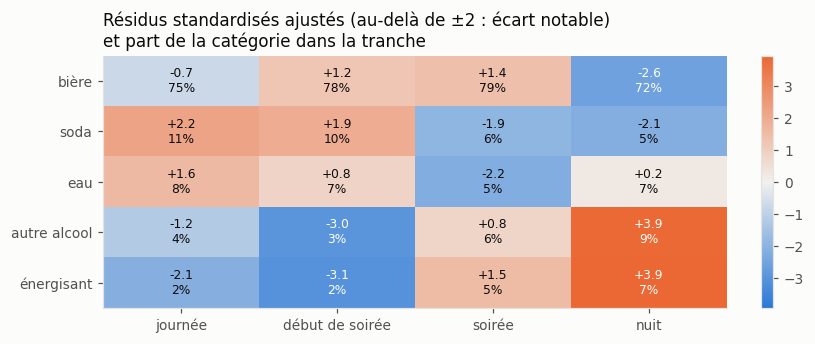

In [31]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
limite = np.abs(residus.to_numpy()).max()
image = ax.imshow(residus.to_numpy(), cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -limite, limite), aspect="auto")
ax.set_xticks(range(4), TRANCHES)
ax.set_yticks(range(len(ORDRE_CATEGORIES)), ORDRE_CATEGORIES)
ax.grid(False)
parts = tableau / tableau.sum()
for (i, j), r in np.ndenumerate(residus.to_numpy()):
    ax.annotate(f"{r:+.1f}\n{parts.iloc[i, j]:.0%}", (j, i), ha="center", va="center", fontsize=8,
                color="white" if abs(r) > limite * 0.6 else TEXTE)
ax.set_title("Résidus standardisés ajustés (au-delà de ±2 : écart notable)\net part de la catégorie dans la tranche")
fig.colorbar(image, ax=ax, fraction=0.03)
fig.tight_layout()
plt.show()

**La composition des commandes change avec l'heure, mais faiblement** (khi2 p = 1e-08, V = 0,09). Les résidus montrent le sens. La nuit, les autres alcools (9 %) et les énergisants (7 %) sont nettement surreprésentés (résidus +3,9), au détriment de la bière et des sodas. En début de soirée, ces deux catégories sont rares (2 à 3 %). Les sodas sont plus fréquents en journée (11 %). La bière reste dominante partout, entre 72 % et 79 %.

La fin de semaine modifie aussi un peu la composition (p = 0,003), avec un effet encore plus faible (V = 0,075).

Ce glissement vers l'alcool fort et les énergisants la nuit est une seconde piste pour la hausse du prix moyen vu en 3.3 : vodys coûte 1 000, contre 600 pour une grande bière.

### 3.5 Quantité, format et prix d'une ligne

In [32]:
lignes_valides = donnees[donnees["format"] != "non précisé"]
grand, petit = lignes_valides.loc[lignes_valides["format"] == "grand", "quantite"], lignes_valides.loc[lignes_valides["format"] == "petit", "quantite"]
p, r = rang_biseriale(petit, grand)
print(f"Quantité moyenne : petit {petit.mean():.2f}, grand {grand.mean():.2f} | plus d'un article : petit {(petit > 1).mean():.1%}, grand {(grand > 1).mean():.1%}")
print(f"Mann-Whitney quantité ~ format : p = {p:.1e}, bisériale (petit vs grand) = {r:.3f}")

rho = stats.spearmanr(donnees["montant_unitaire"], donnees["quantite"])
print(f"Spearman prix unitaire ~ quantité : rho = {rho.statistic:.3f}, p = {rho.pvalue:.1e}")

h, p, e2 = comparer_groupes(donnees[donnees["categorie"] != "plat"], "quantite", "categorie")
print(f"Kruskal-Wallis quantité ~ catégorie : H = {h:.1f}, p = {p:.1e}, epsilon² = {e2:.3f}")
display(donnees.groupby("categorie").agg(lignes=("quantite", "size"), quantite_moyenne=("quantite", "mean"),
                                         plus_d_un=("quantite", lambda s: (s > 1).mean()), prix_median=("montant_unitaire", "median")).round(3))

bieres = donnees[(donnees["categorie"] == "bière") & (donnees["format"] != "non précisé")]
p, r = rang_biseriale(bieres.loc[bieres["format"] == "petit", "quantite"], bieres.loc[bieres["format"] == "grand", "quantite"])
print(f"Bières seulement, quantité petit vs grand : p = {p:.1e}, bisériale = {r:.3f}")

Quantité moyenne : petit 1.85, grand 1.23 | plus d'un article : petit 44.4%, grand 17.1%
Mann-Whitney quantité ~ format : p = 7.5e-45, bisériale (petit vs grand) = 0.287
Spearman prix unitaire ~ quantité : rho = -0.062, p = 1.4e-03
Kruskal-Wallis quantité ~ catégorie : H = 110.1, p = 6.9e-23, epsilon² = 0.041


,lignes,quantite_moyenne,plus_d_un,prix_median
categorie,,,,
autre alcool,143,1.238,0.189,1000.0
bière,1949,1.470,0.281,600.0
eau,158,1.076,0.063,600.0
plat,15,1.200,0.133,800.0
soda,238,1.071,0.071,500.0
énergisant,128,1.070,0.070,500.0


Bières seulement, quantité petit vs grand : p = 2.2e-48, bisériale = 0.334


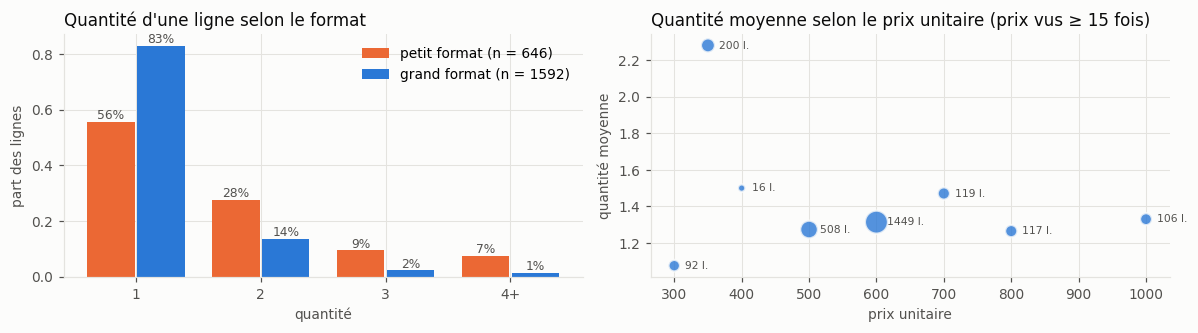

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.1))
for ax, (nom, serie), couleur in zip([axes[0], axes[0]], [("petit format", petit), ("grand format", grand)], [ORANGE, BLEU]):
    parts = serie.clip(upper=4).value_counts(normalize=True).sort_index()
    decalage = -0.2 if nom == "petit format" else 0.2
    ax.bar(parts.index + decalage, parts.values, width=0.38, color=couleur, label=f"{nom} (n = {len(serie)})")
    for x, v in parts.items():
        ax.annotate(f"{v:.0%}", (x + decalage, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8, color=TEXTE_2)
axes[0].set_xticks([1, 2, 3, 4], ["1", "2", "3", "4+"])
axes[0].legend(frameon=False)
axes[0].set(title="Quantité d'une ligne selon le format", xlabel="quantité", ylabel="part des lignes")

prix_q = donnees.groupby("montant_unitaire").agg(lignes=("quantite", "size"), quantite=("quantite", "mean"))
prix_q = prix_q[prix_q["lignes"] >= 15]
axes[1].scatter(prix_q.index, prix_q["quantite"], s=np.sqrt(prix_q["lignes"]) * 6, color=BLEU, alpha=0.8, edgecolor=FOND, linewidth=1.5)
for x, ligne in prix_q.iterrows():
    axes[1].annotate(f"{ligne['lignes']:.0f} l.", (x, ligne["quantite"]), xytext=(7, 0), textcoords="offset points", va="center", fontsize=7, color=TEXTE_2)
axes[1].set(title="Quantité moyenne selon le prix unitaire (prix vus ≥ 15 fois)", xlabel="prix unitaire", ylabel="quantité moyenne")
fig.tight_layout()
plt.show()

**Les petits formats s'achètent par plusieurs.** 44,4 % des lignes en petit format portent plus d'un article, contre 17,1 % en grand format (Mann-Whitney p = 7e-45, bisériale 0,29). Le résultat tient parmi les seules bières (bisériale 0,33). Les clients semblent compenser le petit volume par le nombre : les petites bières à 350 sont prises en moyenne par 2,3.

Le prix seul n'explique pas la quantité (Spearman rho = -0,06). Les sodas à 300 et les eaux sont presque toujours pris à l'unité (7 % et 6 % de lignes à plusieurs articles). La quantité dépend de la catégorie (p = 7e-23, epsilon² = 0,04) : c'est la bière en petit format qui porte les achats multiples.

### 3.6 Vue d'ensemble : toutes les paires au niveau commande

Neuf variables de commande sont croisées deux à deux (36 paires). Le test dépend des types : Spearman entre deux numériques, Kruskal-Wallis entre une numérique et une catégorielle, khi2 (V de Cramér) entre deux catégorielles. Les p-values sont corrigées par Holm. Pour que les effets soient sur la même échelle, celui de Kruskal-Wallis est la racine de l'epsilon², comparable à une corrélation.

In [34]:
periode_cmd["plusieurs_categories"] = periode_cmd["categories"] > 1
NUMERIQUES = ["montant", "articles", "lignes", "prix_moyen"]
CATEGORIELLES = ["tranche", "fin_de_semaine", "samedi_nuit", "categorie_dominante", "plusieurs_categories"]
NOMS = {"montant": "Montant", "articles": "Articles", "lignes": "Lignes", "prix_moyen": "Prix moyen", "tranche": "Tranche horaire",
        "fin_de_semaine": "Fin de semaine", "samedi_nuit": "Samedi nuit", "categorie_dominante": "Catégorie dominante",
        "plusieurs_categories": "Plusieurs catégories"}
table_paires = periode_cmd[periode_cmd["categorie_dominante"] != "plat"]


def tester_paire(t, a, b):
    if a in NUMERIQUES and b in NUMERIQUES:
        r = stats.spearmanr(t[a], t[b])
        return "Spearman", abs(r.statistic), r.pvalue
    if a in NUMERIQUES or b in NUMERIQUES:
        num, cat = (a, b) if a in NUMERIQUES else (b, a)
        h, p, e2 = comparer_groupes(t, num, cat)
        return "Kruskal (racine epsilon²)", np.sqrt(max(e2, 0)), p
    _, p, _, v, _ = v_cramer(pd.crosstab(t[a], t[b]))
    return "khi2 (V)", v, p


variables = NUMERIQUES + CATEGORIELLES
resultats = pd.DataFrame([dict(zip(["variable_1", "variable_2", "test", "effet", "p"], [a, b, *tester_paire(table_paires, a, b)]))
                          for i, a in enumerate(variables) for b in variables[i + 1:]])
resultats["p_holm"] = multipletests(resultats["p"], method="holm")[1]
display(resultats.sort_values("effet", ascending=False).round(4).reset_index(drop=True))
print(f"{(resultats['p_holm'] < 0.05).sum()} paires significatives sur {len(resultats)} après Holm")

,variable_1,variable_2,test,effet,p,p_holm
0,montant,articles,Spearman,0.8553,0.0000,0.0000
1,lignes,plusieurs_categories,Kruskal (racine epsilon²),0.6962,0.0000,0.0000
2,articles,lignes,Spearman,0.6488,0.0000,0.0000
3,montant,lignes,Spearman,0.5693,0.0000,0.0000
4,prix_moyen,categorie_dominante,Kruskal (racine epsilon²),0.4738,0.0000,0.0000
5,montant,categorie_dominante,Kruskal (racine epsilon²),0.4455,0.0000,0.0000
6,articles,plusieurs_categories,Kruskal (racine epsilon²),0.4440,0.0000,0.0000
7,montant,prix_moyen,Spearman,0.4289,0.0000,0.0000
8,montant,plusieurs_categories,Kruskal (racine epsilon²),0.3847,0.0000,0.0000
9,fin_de_semaine,samedi_nuit,khi2 (V),0.3668,0.0000,0.0000


21 paires significatives sur 36 après Holm


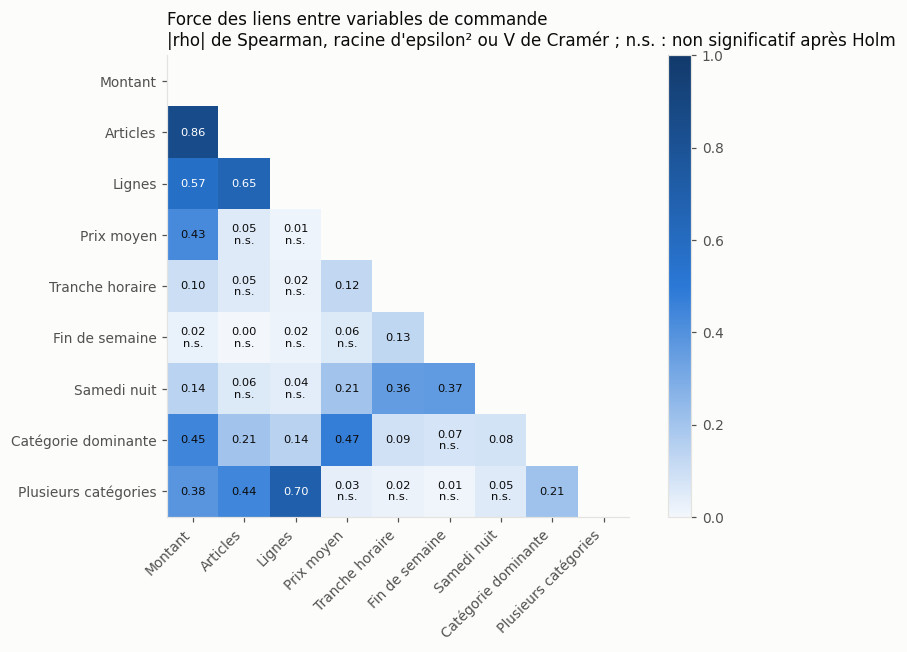

In [35]:
carte = pd.DataFrame(np.nan, index=variables, columns=variables)
signif = pd.DataFrame(False, index=variables, columns=variables)
for _, ligne in resultats.iterrows():
    carte.loc[ligne["variable_2"], ligne["variable_1"]] = ligne["effet"]
    signif.loc[ligne["variable_2"], ligne["variable_1"]] = ligne["p_holm"] < 0.05

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(carte.to_numpy(dtype=float), cmap=RAMPE, vmin=0, vmax=1)
noms = [NOMS[v] for v in variables]
ax.set_xticks(range(len(variables)), noms, rotation=45, ha="right")
ax.set_yticks(range(len(variables)), noms)
ax.grid(False)
for (i, j), v in np.ndenumerate(carte.to_numpy(dtype=float)):
    if not np.isnan(v):
        etoile = "" if signif.iloc[i, j] else "\nn.s."
        ax.annotate(f"{v:.2f}{etoile}", (j, i), ha="center", va="center", fontsize=7.5, color="white" if v > 0.55 else TEXTE)
ax.set_title("Force des liens entre variables de commande\n|rho| de Spearman, racine d'epsilon² ou V de Cramér ; n.s. : non significatif après Holm")
fig.colorbar(image, ax=ax, fraction=0.04)
fig.tight_layout()
plt.show()

21 paires sur 36 sont significatives après Holm, mais **les liens forts sont presque tous structurels**. Le montant suit le nombre d'articles (rho = 0,86), qui suit le nombre de lignes (0,65). Une commande à plusieurs catégories a forcément plusieurs lignes (0,70). `samedi_nuit` est construit à partir de la tranche et du jour (0,36 et 0,37). Ces liens viennent de la construction des variables et n'apprennent rien.

Les liens informatifs sont plus modestes :

- **Catégorie dominante → prix moyen (0,47) et montant (0,45) :** le type de boisson fixe le prix (vodys à 1 000, soda à 300-500).
- **Samedi nuit → prix moyen (0,21) :** c'est la majoration de la section 3.1.
- **Tranche horaire → prix moyen (0,12) et montant (0,10) :** faible.
- **Le moment n'a aucun lien avec la taille du panier :** articles et lignes ne dépendent ni de la tranche ni de la fin de semaine (tous non significatifs après Holm).

Le moment agit donc sur **le prix payé par article**, pas sur la quantité. Il reste à savoir si cet effet passe par la majoration ou par la composition des commandes.

## 4. Analyse multivariée

### 4.1 Pourquoi la nuit coûte plus cher : majoration ou composition ?

Pour séparer les deux effets, je recalcule chaque commande **au prix de référence** de ses produits (section 3.1), c'est-à-dire sans majoration ni réduction. Si l'écart entre tranches persiste à prix de référence, il vient de ce qui est commandé. S'il disparaît, il vient du tarif.

In [36]:
donnees["sous_total_reference"] = donnees["produit_net"].map(reference) * donnees["quantite"]
reference_cmd = donnees.groupby("n_commande")["sous_total_reference"].sum()
periode_cmd["montant_reference"] = reference_cmd
periode_cmd["prix_reference"] = periode_cmd["montant_reference"] / periode_cmd["articles"]

lignes_tab = []
for nom, table in [("toutes les commandes", periode_cmd), ("hors samedi nuit", periode_cmd[~periode_cmd["samedi_nuit"]])]:
    for valeur in ["prix_moyen", "prix_reference"]:
        h, p, e2 = comparer_groupes(table, valeur, "tranche")
        moyennes = table.groupby("tranche", observed=True)[valeur].mean().round(0).to_dict()
        lignes_tab.append({"commandes": nom, "variable": valeur, "p Kruskal": p, "racine epsilon²": np.sqrt(max(e2, 0)), **moyennes})
display(pd.DataFrame(lignes_tab).round(4))

,commandes,variable,p Kruskal,racine epsilon²,journée,début de soirée,soirée,nuit
0,toutes les commandes,prix_moyen,0.0000,0.1229,570.0,567.0,588.0,614.0
1,toutes les commandes,prix_reference,0.2395,0.0239,580.0,573.0,587.0,602.0
2,hors samedi nuit,prix_moyen,0.0985,0.0415,570.0,567.0,581.0,594.0
3,hors samedi nuit,prix_reference,0.2505,0.0241,580.0,573.0,587.0,603.0


Je stratifie ensuite par catégorie dominante : à catégorie fixée, le prix de référence varie-t-il encore selon la tranche ? Les p-values des strates sont combinées par la méthode de Fisher.

In [37]:
strates = []
for cat in ORDRE_CATEGORIES:
    g = periode_cmd[periode_cmd["categorie_dominante"] == cat]
    h, p, e2 = comparer_groupes(g, "prix_reference", "tranche")
    strates.append({"catégorie": cat, "commandes": len(g), "p Kruskal": p, "racine epsilon²": np.sqrt(max(e2, 0)),
                    **g.groupby("tranche", observed=True)["prix_reference"].mean().round(0).to_dict()})
strates = pd.DataFrame(strates)
display(strates.round(4))
print("Combinaison de Fisher des strates :", stats.combine_pvalues(strates["p Kruskal"], method="fisher"))

,catégorie,commandes,p Kruskal,racine epsilon²,journée,début de soirée,soirée,nuit
0,bière,1621,0.9434,0.0000,588.0,590.0,589.0,593.0
1,soda,167,0.5063,0.0000,393.0,417.0,413.0,425.0
2,eau,133,0.2246,0.1029,571.0,579.0,590.0,582.0
3,autre alcool,109,0.0027,0.3257,990.0,635.0,811.0,851.0
4,énergisant,79,0.9684,0.0000,533.0,523.0,515.0,510.0


Combinaison de Fisher des strates : SignificanceResult(statistic=np.float64(16.343583522138907), pvalue=np.float64(0.09021030775110059))


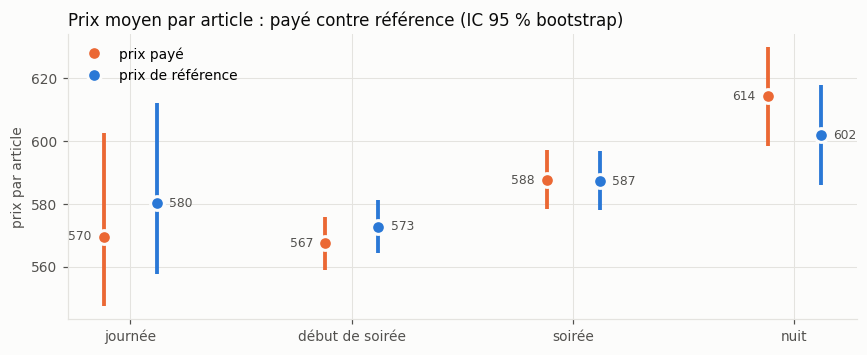

In [38]:
fig, ax = plt.subplots(figsize=(8, 3.3))
for decalage, valeur, couleur, nom in [(-0.12, "prix_moyen", ORANGE, "prix payé"), (0.12, "prix_reference", BLEU, "prix de référence")]:
    for i, tranche in enumerate(TRANCHES):
        serie = periode_cmd.loc[periode_cmd["tranche"] == tranche, valeur].to_numpy()
        ic = stats.bootstrap((serie,), np.mean, n_resamples=3000, method="percentile", batch=250, random_state=0).confidence_interval
        ax.vlines(i + decalage, ic.low, ic.high, color=couleur, linewidth=2.5)
        ax.plot(i + decalage, serie.mean(), "o", color=couleur, markersize=9, markeredgecolor=FOND, markeredgewidth=2,
                label=nom if i == 0 else None)
        ax.annotate(f"{serie.mean():.0f}", (i + decalage, serie.mean()), xytext=(-8 if decalage < 0 else 8, 0),
                    textcoords="offset points", ha="right" if decalage < 0 else "left", va="center", fontsize=8, color=TEXTE_2)
ax.set_xticks(range(4), TRANCHES)
ax.legend(frameon=False, loc="upper left")
ax.set(title="Prix moyen par article : payé contre référence (IC 95 % bootstrap)", ylabel="prix par article")
fig.tight_layout()
plt.show()

**La hausse du prix la nuit vient de la majoration, pas de ce qui est commandé.**

- Au prix payé, le prix moyen par article monte de 567 à 614 entre le début de soirée et la nuit (p = 1e-07).
- Au prix de référence, l'écart se réduit à 573 contre 602, et il n'est plus significatif (p = 0,24, effet 0,02).
- En retirant seulement les commandes du samedi nuit, l'écart au prix payé n'est plus significatif non plus (p = 0,10).
- À catégorie fixée, le prix de référence ne varie pas selon la tranche pour la bière, les sodas, l'eau et les énergisants (p de 0,22 à 0,97). Seuls les autres alcools varient (p = 0,003) : vodys domine en journée, et la tequila, moins chère, la nuit. La combinaison des strates n'est pas significative (p = 0,09).

Le glissement vers l'alcool fort la nuit (section 3.4) existe donc, mais il est trop faible pour changer le prix moyen. Ce qui rend la nuit plus chère, c'est le tarif du samedi soir.

### 4.2 Le glissement nocturne vers l'alcool fort et les énergisants tient-il à jour fixé ?

La nuit et la fin de semaine sont liées (V = 0,13) : le glissement vu en 3.4 pourrait venir des samedis. Le test de Cochran-Mantel-Haenszel mesure le lien nuit × (autre alcool ou énergisant) à fin de semaine fixée. Le test de Breslow-Day vérifie que ce lien a la même force dans les deux strates.

In [39]:
from statsmodels.stats.contingency_tables import StratifiedTable

periode_cmd["nuit"] = periode_cmd["tranche"] == "nuit"
periode_cmd["fort_ou_energisant"] = periode_cmd["categorie_dominante"].isin(["autre alcool", "énergisant"])


def tableau_2x2(t, a, b):
    return pd.crosstab(t[a], t[b]).reindex(index=[True, False], columns=[True, False], fill_value=0).to_numpy()


strates_cmh = {f"fin de semaine = {cle}": tableau_2x2(g, "nuit", "fort_ou_energisant") for cle, g in periode_cmd.groupby("fin_de_semaine")}
for nom, t in strates_cmh.items():
    print(nom, "| part la nuit :", round(t[0, 0] / t[0].sum(), 3), "| hors nuit :", round(t[1, 0] / t[1].sum(), 3),
          "| odds ratio :", round(t[0, 0] * t[1, 1] / (t[0, 1] * t[1, 0]), 2))
brut_or = stats.contingency.odds_ratio(tableau_2x2(periode_cmd, "nuit", "fort_ou_energisant")).statistic
strat = StratifiedTable(list(strates_cmh.values()))
print(f"Odds ratio brut : {brut_or:.2f}")
print(f"Odds ratio de Mantel-Haenszel : {strat.oddsratio_pooled:.2f}, IC 95 % {np.round(strat.oddsratio_pooled_confint(), 2)}")
print(f"CMH : p = {strat.test_null_odds().pvalue:.1e} | Breslow-Day (homogénéité) : p = {strat.test_equal_odds().pvalue:.3f}")

fin de semaine = False | part la nuit : 0.174 | hors nuit : 0.072 | odds ratio : 2.73
fin de semaine = True | part la nuit : 0.163 | hors nuit : 0.075 | odds ratio : 2.4
Odds ratio brut : 2.55
Odds ratio de Mantel-Haenszel : 2.54, IC 95 % [1.82 3.56]
CMH : p = 2.0e-08 | Breslow-Day (homogénéité) : p = 0.708


**Le glissement nocturne n'est pas un effet du samedi.** Une commande de nuit est dominée par un alcool fort ou un énergisant dans 17,4 % des cas en semaine et 16,3 % en fin de semaine, contre 7 à 7,5 % aux autres heures. L'odds ratio vaut 2,73 en semaine et 2,40 en fin de semaine. Le test de Breslow-Day ne rejette pas l'égalité des deux (p = 0,71). L'odds ratio de Mantel-Haenszel, 2,54 (IC 95 % [1,82 ; 3,56]), est pratiquement égal au brut (2,55) : la fin de semaine ne confond pas ce lien. **La nuit, la probabilité de commander un alcool fort ou un énergisant est environ 2,5 fois plus élevée, quel que soit le jour.**

### 4.3 Quels produits sont commandés ensemble ?

L'analyse porte sur les 385 commandes de plusieurs produits. Les comparer à l'ensemble des commandes gonflerait tous les liens, puisque 82 % des commandes n'ont qu'un produit. Pour chaque paire de produits fréquents, le **lift** compare la fréquence observée de la paire à celle attendue si les deux produits étaient choisis indépendamment. Un lift de 2 signifie que la paire apparaît deux fois plus souvent que par hasard. Le test exact de Fisher est unilatéral (association positive), avec une correction de Holm.

In [40]:
from itertools import combinations

presence = pd.crosstab(donnees["n_commande"], donnees["produit_net"]).clip(upper=1)
multiples = presence[presence.sum(axis=1) > 1]
frequents = multiples.sum().sort_values(ascending=False)
frequents = frequents[frequents >= 20].index.tolist()
print(f"{len(multiples)} commandes de plusieurs produits ; {len(frequents)} produits présents dans au moins 20 d'entre elles")

n_mult = len(multiples)
paires = []
for a, b in combinations(frequents, 2):
    t = pd.crosstab(multiples[a], multiples[b]).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
    attendu = multiples[a].sum() * multiples[b].sum() / n_mult
    paires.append({"produit_a": a, "produit_b": b, "ensemble": t[0, 0], "attendu": attendu, "lift": t[0, 0] / attendu,
                   "p": stats.fisher_exact(t, alternative="greater")[1]})
paires = pd.DataFrame(paires)
paires["p_holm"] = multipletests(paires["p"], method="holm")[1]
display(paires.sort_values("lift", ascending=False).head(12).round(3))
print(f"Paires testées : {len(paires)} | significatives après Holm : {(paires['p_holm'] < 0.05).sum()}")

386 commandes de plusieurs produits ; 16 produits présents dans au moins 20 d'entre elles


,produit_a,produit_b,ensemble,attendu,lift,p,p_holm
71,La Beninoise 65cl (Grande),La Beninoise 33cl (Petite),15,3.907,3.840,0.000,0.0
105,XXL,Eau Fifa 1.5L (Grande),5,2.487,2.010,0.090,1.0
112,Eau Fifa 1.5L (Grande),Youki Cocktail 65 cl Bouteille (Grande),4,2.021,1.979,0.132,1.0
67,La Beninoise 65cl (Grande),Kankpe 33cl (Petite),9,4.984,1.806,0.044,1.0
95,Kankpe 33cl (Petite),La Beninoise 33cl (Petite),5,2.780,1.799,0.131,1.0
75,Beaufort 33cl (Petite),vodys,8,4.567,1.752,0.068,1.0
41,Doppel Munich 65cl (Noir) (Grande),Doppel Energy,5,3.158,1.583,0.195,1.0
83,Beaufort 33cl (Petite),Doppel Energy,4,2.562,1.561,0.246,1.0
84,vodys,Kankpe 33cl (Petite),6,3.930,1.527,0.185,1.0
40,Doppel Munich 65cl (Noir) (Grande),Youki Cocktail 65 cl Bouteille (Grande),5,3.570,1.401,0.277,1.0


Paires testées : 120 | significatives après Holm : 1


Je refais l'analyse au niveau des catégories, et je compare petit et grand format, qui ressortent dans les paires.

In [41]:
presence_cat = pd.crosstab(donnees["n_commande"], donnees["categorie"]).clip(upper=1)
presence_cat = presence_cat.loc[multiples.index]
lift_cat = pd.DataFrame(np.nan, index=ORDRE_CATEGORIES, columns=ORDRE_CATEGORIES)
p_cat = []
for a, b in combinations(ORDRE_CATEGORIES, 2):
    t = pd.crosstab(presence_cat[a], presence_cat[b]).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
    attendu = presence_cat[a].sum() * presence_cat[b].sum() / n_mult
    lift_cat.loc[a, b] = lift_cat.loc[b, a] = t[0, 0] / attendu
    p_cat.append({"paire": f"{a} + {b}", "ensemble": t[0, 0], "lift": t[0, 0] / attendu, "p (2 côtés)": stats.fisher_exact(t)[1]})
p_cat = pd.DataFrame(p_cat)
p_cat["p_holm"] = multipletests(p_cat["p (2 côtés)"], method="holm")[1]
display(p_cat.sort_values("lift", ascending=False).round(3))

donnees["formats_cle"] = donnees["format"].where(donnees["format"] != "non précisé")
presence_fmt = pd.crosstab(donnees["n_commande"], donnees["formats_cle"]).clip(upper=1).reindex(multiples.index, fill_value=0)
t = pd.crosstab(presence_fmt["petit"], presence_fmt["grand"]).reindex(index=[1, 0], columns=[1, 0]).to_numpy()
print("Petit + grand format dans la même commande :", t[0, 0], "| attendu :", round(presence_fmt["petit"].sum() * presence_fmt["grand"].sum() / n_mult, 1),
      "| Fisher bilatéral p =", f"{stats.fisher_exact(t)[1]:.3f}")

,paire,ensemble,lift,p (2 côtés),p_holm
8,eau + énergisant,8,1.167,0.659,1.000
4,soda + eau,9,0.999,1.000,1.000
3,bière + énergisant,48,0.956,0.244,1.000
2,bière + autre alcool,58,0.931,0.033,0.265
0,bière + soda,57,0.863,0.000,0.000
1,bière + eau,38,0.834,0.000,0.001
5,soda + autre alcool,9,0.730,0.300,1.000
7,eau + autre alcool,5,0.588,0.224,1.000
9,autre alcool + énergisant,5,0.533,0.120,0.718
6,soda + énergisant,5,0.503,0.086,0.603


Petit + grand format dans la même commande : 136 | attendu : 162.7 | Fisher bilatéral p = 0.000


In [42]:
anciennes = set(donnees.loc[~donnees["produit"].str.contains(r"\(", regex=True) & donnees["cle"].str.contains("beninoise|kankpe|pils benin"), "n_commande"])
paire = multiples[(multiples["La Beninoise 65cl (Grande)"] == 1) & (multiples["La Beninoise 33cl (Petite)"] == 1)].index
print(f"Commandes avec les deux La Beninoise : {len(paire)}, dont {len(set(paire) & anciennes)} avec un libellé ancien")
sans_anciennes = multiples.drop(index=list(anciennes & set(multiples.index)))
t = pd.crosstab(sans_anciennes["La Beninoise 65cl (Grande)"], sans_anciennes["La Beninoise 33cl (Petite)"]).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
attendu = sans_anciennes["La Beninoise 65cl (Grande)"].sum() * sans_anciennes["La Beninoise 33cl (Petite)"].sum() / len(sans_anciennes)
print(f"Sans les commandes au libellé ancien : ensemble {t[0, 0]}, attendu {attendu:.2f}, lift {t[0, 0] / attendu:.2f}, "
      f"Fisher p = {stats.fisher_exact(t, alternative='greater')[1]:.3f}")

Commandes avec les deux La Beninoise : 15, dont 13 avec un libellé ancien
Sans les commandes au libellé ancien : ensemble 2, attendu 1.54, lift 1.30, Fisher p = 0.468


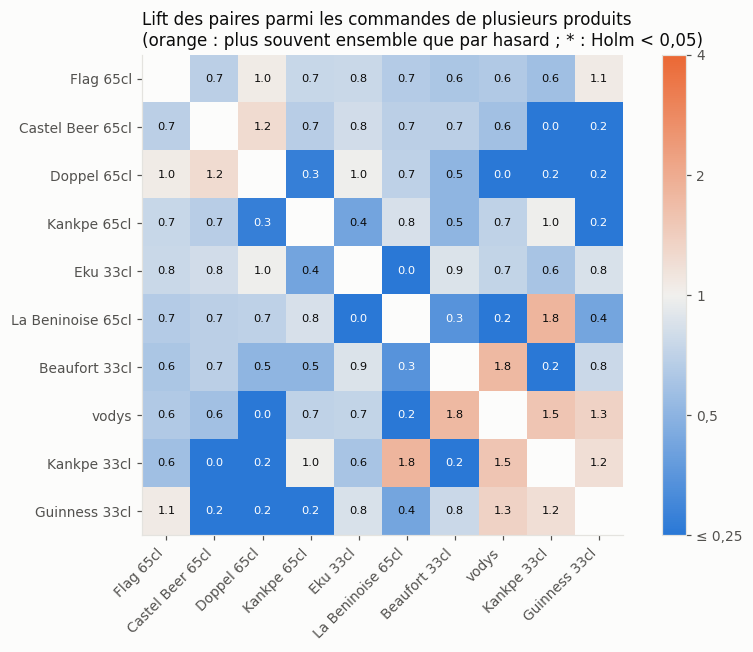

In [43]:
top = frequents[:10]
matrice = pd.DataFrame(np.nan, index=top, columns=top)
signif = pd.DataFrame(False, index=top, columns=top)
for _, ligne in paires.iterrows():
    if ligne["produit_a"] in top and ligne["produit_b"] in top:
        for a, b in [(ligne["produit_a"], ligne["produit_b"]), (ligne["produit_b"], ligne["produit_a"])]:
            matrice.loc[a, b] = ligne["lift"]
            signif.loc[a, b] = ligne["p_holm"] < 0.05
courts = [re.sub(r"\s*\((Grande|Petite|Noir)\)", "", p).replace("Doppel Munich", "Doppel") for p in top]
echelle = np.log2(matrice.clip(lower=0.25).to_numpy(dtype=float))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(echelle, cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -2, 2))
ax.set_xticks(range(len(top)), courts, rotation=45, ha="right")
ax.set_yticks(range(len(top)), courts)
ax.grid(False)
for (i, j), v in np.ndenumerate(matrice.to_numpy(dtype=float)):
    if not np.isnan(v):
        ax.annotate(f"{v:.1f}" + ("*" if signif.iloc[i, j] else ""), (j, i), ha="center", va="center", fontsize=7.5,
                    color="white" if abs(echelle[i, j]) > 1.3 else TEXTE)
barre = fig.colorbar(image, ax=ax, fraction=0.04)
barre.set_ticks([-2, -1, 0, 1, 2], labels=["≤ 0,25", "0,5", "1", "2", "4"])
ax.set_title("Lift des paires parmi les commandes de plusieurs produits\n(orange : plus souvent ensemble que par hasard ; * : Holm < 0,05)")
fig.tight_layout()
plt.show()

**Il n'y a pas de paire de produits privilégiée.** Sur 120 paires testées, une seule résiste à la correction de Holm : La Beninoise 65cl avec La Beninoise 33cl (lift 3,8). Mais 13 des 15 commandes concernées portent un libellé ancien (section 1.2). Sans elles, le lift tombe à 1,3 et n'est plus significatif (p = 0,47). Ce lien venait donc du catalogue de la phase de démarrage, pas d'une habitude de consommation.

La carte est surtout bleue, et c'est attendu. Une commande de 2 ou 3 produits ne peut pas contenir deux fois le même : deux produits très demandés se retrouvent donc mécaniquement moins souvent ensemble que l'indépendance ne le prévoit. Seuls les lifts nettement au-dessus de 1 seraient informatifs. Ceux qui dépassent 1,5 (Beaufort + vodys, vodys + Kankpe 33cl, La Beninoise 65cl + Kankpe 33cl) reposent sur 5 à 9 commandes, et aucun n'est significatif.

Deux tendances se dégagent au niveau des catégories et des formats :

- La bière se combine moins que prévu avec le soda (lift 0,86, Holm p < 0,001) et avec l'eau (0,83, p = 0,001). Les commandes de plusieurs produits sont plutôt entièrement à base de bière, ou entièrement sans alcool.
- Petit et grand format sont moins souvent mélangés que prévu (136 commandes contre 163 attendues, p < 0,001). Un client garde plutôt le même format.

### 4.4 ACP des variables numériques de commande

Quatre variables numériques actives décrivent une commande : articles, lignes, prix moyen et nombre de catégories. Articles et prix moyen sont passés au logarithme, car ils sont très asymétriques.

**Le montant n'est pas une variable active.** Par construction, log(montant) = log(articles) + log(prix moyen) : l'inclure créerait une dépendance exacte, avec une valeur propre nulle et un KMO dégradé (essai fait : KMO 0,46, 5e valeur propre 0,02). Il est projeté comme variable supplémentaire.

Avant l'ACP, je vérifie que les variables sont assez corrélées pour être résumées (test de sphéricité de Bartlett et indice KMO).

In [44]:
acp_vars = pd.DataFrame({"log_articles": np.log(periode_cmd["articles"]),
                         "lignes": periode_cmd["lignes"], "log_prix_moyen": np.log(periode_cmd["prix_moyen"]),
                         "categories": periode_cmd["categories"]})
corr = acp_vars.corr().to_numpy()
n, p = acp_vars.shape
khi2_bartlett = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(corr))
print(f"Bartlett : khi2 = {khi2_bartlett:.0f}, ddl = {p * (p - 1) // 2}, p = {stats.chi2.sf(khi2_bartlett, p * (p - 1) // 2):.1e}")
inverse = np.linalg.inv(corr)
partielle = -inverse / np.sqrt(np.outer(np.diag(inverse), np.diag(inverse)))
masque = ~np.eye(p, dtype=bool)
kmo_global = (corr[masque] ** 2).sum() / ((corr[masque] ** 2).sum() + (partielle[masque] ** 2).sum())
kmo_vars = (corr ** 2 * masque).sum(axis=0) / ((corr ** 2 * masque).sum(axis=0) + (partielle ** 2 * masque).sum(axis=0))
print(f"KMO global : {kmo_global:.2f} |", dict(zip(acp_vars.columns, kmo_vars.round(2))))

valeurs, vecteurs = np.linalg.eigh(corr)
ordre = np.argsort(valeurs)[::-1]
valeurs, vecteurs = valeurs[ordre], vecteurs[:, ordre]
vecteurs = vecteurs * np.sign(vecteurs[np.abs(vecteurs).argmax(axis=0), np.arange(p)])
inertie = pd.DataFrame({"valeur propre": valeurs, "part": valeurs / p, "part cumulée": np.cumsum(valeurs) / p},
                       index=[f"PC{i + 1}" for i in range(p)])
display(inertie.round(3))
saturations = pd.DataFrame(vecteurs * np.sqrt(valeurs), index=acp_vars.columns, columns=inertie.index)
centrees = ((acp_vars - acp_vars.mean()) / acp_vars.std()).to_numpy()
coordonnees = pd.DataFrame(centrees @ vecteurs[:, :2], columns=["PC1", "PC2"], index=periode_cmd.index)
supplementaire = {nom: [np.corrcoef(serie, coordonnees[c])[0, 1] for c in ["PC1", "PC2"]]
                  for nom, serie in {"log_montant": np.log(periode_cmd["montant"]), "heure_nuit": periode_cmd["nuit"].astype(float),
                                     "samedi_nuit": periode_cmd["samedi_nuit"].astype(float)}.items()}
saturations_sup = pd.DataFrame(supplementaire, index=["PC1", "PC2"]).T
display(pd.concat({"actives": saturations.iloc[:, :2], "supplémentaires": saturations_sup}).round(3))

Bartlett : khi2 = 2733, ddl = 6, p = 0.0e+00
KMO global : 0.62 | {'log_articles': np.float64(0.68), 'lignes': np.float64(0.58), 'log_prix_moyen': np.float64(0.23), 'categories': np.float64(0.63)}


,valeur propre,part,part cumulée
PC1,2.213,0.553,0.553
PC2,1.009,0.252,0.806
PC3,0.558,0.139,0.945
PC4,0.220,0.055,1.000


PC1    PC2
actives         log_articles    0.797 -0.119
                lignes          0.928  0.044
                log_prix_moyen  0.005  0.995
                categories      0.847  0.058
supplémentaires log_montant     0.744  0.305
                heure_nuit      0.010  0.096
                samedi_nuit     0.060  0.150

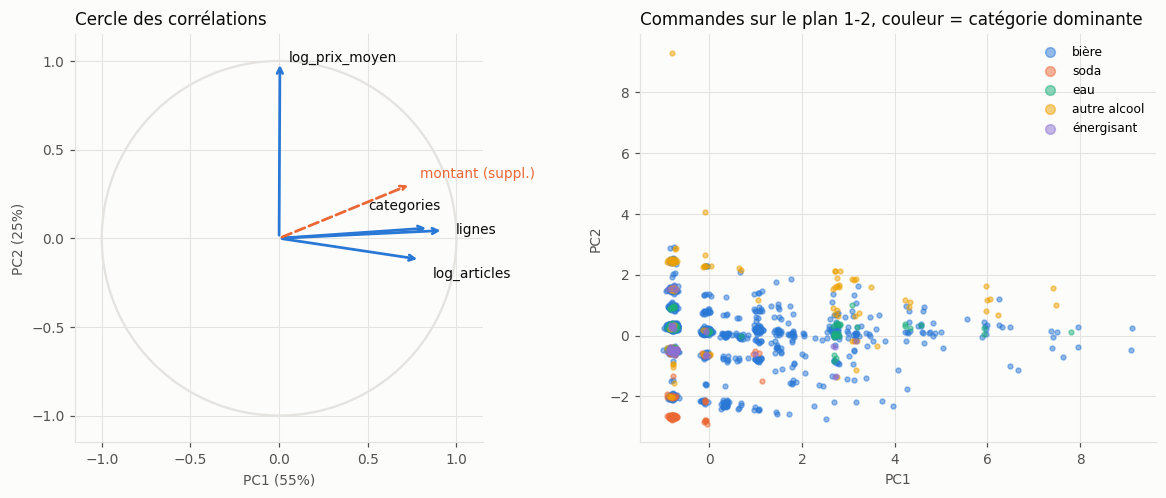

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
cercle = np.linspace(0, 2 * np.pi, 200)
axes[0].plot(np.cos(cercle), np.sin(cercle), color=GRILLE)
decalages = {"log_articles": (8, -12), "lignes": (8, -2), "categories": (-40, 12), "log_prix_moyen": (6, 0)}
for var, (x, y) in saturations.iloc[:, :2].iterrows():
    axes[0].annotate("", (x, y), (0, 0), arrowprops={"arrowstyle": "->", "color": BLEU, "linewidth": 1.8})
    axes[0].annotate(var, (x, y), xytext=decalages[var], textcoords="offset points", color=TEXTE)
x, y = saturations_sup.loc["log_montant"]
axes[0].annotate("", (x, y), (0, 0), arrowprops={"arrowstyle": "->", "color": ORANGE, "linewidth": 1.8, "linestyle": "--"})
axes[0].annotate("montant (suppl.)", (x, y), xytext=(6, 4), textcoords="offset points", color=ORANGE)
axes[0].set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect="equal",
            title="Cercle des corrélations", xlabel=f"PC1 ({inertie.iloc[0, 1]:.0%})", ylabel=f"PC2 ({inertie.iloc[1, 1]:.0%})")
for cat in ORDRE_CATEGORIES:
    masque_cat = periode_cmd["categorie_dominante"] == cat
    axes[1].scatter(coordonnees.loc[masque_cat, "PC1"] + np.random.default_rng(0).normal(0, 0.05, masque_cat.sum()),
                    coordonnees.loc[masque_cat, "PC2"] + np.random.default_rng(1).normal(0, 0.05, masque_cat.sum()),
                    s=10, alpha=0.5, color=COULEUR_CATEGORIE[cat], label=cat)
axes[1].legend(frameon=False, markerscale=2, fontsize=8)
axes[1].set(title="Commandes sur le plan 1-2, couleur = catégorie dominante", xlabel="PC1", ylabel="PC2")
fig.tight_layout()
plt.show()

L'ACP est légitime : Bartlett rejette la sphéricité (p ≈ 0) et le KMO global vaut 0,62, ce qui est moyen mais acceptable. Le prix moyen a un KMO individuel faible (0,23), parce qu'il est presque indépendant des autres variables. Il forme donc un axe à lui seul.

Deux axes résument 81 % de l'information, et ils sont presque orthogonaux par nature :

- **PC1 (55 %) : la taille du panier.** Lignes (0,93), catégories (0,85) et articles (0,80) y sont fortement corrélés.
- **PC2 (25 %) : le prix par article.** Il est porté par le seul prix moyen (0,995).

Le montant, projeté en supplémentaire, est lié surtout à PC1 (0,74) et un peu à PC2 (0,31) : **la valeur d'une commande dépend d'abord du nombre d'articles, ensuite seulement de leur prix**. La nuit et le samedi nuit sont presque sans lien avec les deux axes (corrélations ≤ 0,15). L'effet du moment, réel mais faible (sections 3.3 et 4.1), ne structure pas les commandes.

Sur le nuage, les commandes simples forment des bandes horizontales à gauche : une bande par prix unitaire. Les autres alcools (jaune) sont en haut, les sodas (orange) en bas. Le point isolé tout en haut est le vin à 5 000.

### 4.5 ACM des caractéristiques qualitatives des commandes

L'ACM résume les liens entre six variables qualitatives de commande : tranche horaire, fin de semaine, catégorie dominante, taille (1, 2, 3 articles ou plus), format dominant et tarif de la commande (normal, majoré ou réduit si au moins une ligne l'est). Les commandes dominées par un plat sont exclues, car trop rares.

In [46]:
import prince

tarif_cmd = donnees.groupby("n_commande")["tarif"].agg(lambda s: "majoré" if (s == "majoré").any() else "réduit" if (s == "réduit").any() else "normal")
format_cmd = donnees.sort_values("sous_total", ascending=False).drop_duplicates("n_commande").set_index("n_commande")["format"]
acm_table = pd.DataFrame({
    "tranche": periode_cmd["tranche"].astype(str),
    "semaine": np.where(periode_cmd["fin_de_semaine"], "sam-dim", "lun-ven"),
    "categorie": periode_cmd["categorie_dominante"],
    "taille": pd.cut(periode_cmd["articles"], [0, 1, 2, np.inf], labels=["1 article", "2 articles", "3+ articles"]).astype(str),
    "format": periode_cmd.index.map(format_cmd),
    "tarif": periode_cmd.index.map(tarif_cmd),
}, index=periode_cmd.index)
acm_table = acm_table[acm_table["categorie"] != "plat"]
for col in acm_table:
    print(col, acm_table[col].value_counts().to_dict())

acm = prince.MCA(n_components=5, random_state=0).fit(acm_table)
display(acm.eigenvalues_summary)
print(f"Seuil de Kaiser en ACM : 1 / {acm_table.shape[1]} = {1 / acm_table.shape[1]:.3f}")

tranche {'soirée': 738, 'début de soirée': 679, 'nuit': 352, 'journée': 340}
semaine {'lun-ven': 1176, 'sam-dim': 933}
categorie {'bière': 1621, 'soda': 167, 'eau': 133, 'autre alcool': 109, 'énergisant': 79}
taille {'1 article': 1343, '2 articles': 454, '3+ articles': 312}
format {'grand': 1317, 'petit': 506, 'non précisé': 286}
tarif {'normal': 1845, 'réduit': 138, 'majoré': 126}


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.326,13.97%,13.97%
1,0.254,10.90%,24.88%
2,0.216,9.25%,34.13%
3,0.196,8.39%,42.52%
4,0.180,7.72%,50.24%


Seuil de Kaiser en ACM : 1 / 6 = 0.167


Les pourcentages bruts de l'ACM sous-estiment toujours l'information des premiers axes, car le codage disjonctif crée de l'inertie artificielle. La correction de Benzécri ne garde que les valeurs propres au-dessus de 1/Q et les réévalue.

In [47]:
Q = acm_table.shape[1]
valeurs_acm = acm.eigenvalues_
corrigees = np.where(valeurs_acm > 1 / Q, (Q / (Q - 1) * (valeurs_acm - 1 / Q)) ** 2, 0)
print("Inertie corrigée (Benzécri) :", dict(zip([f"axe {i + 1}" for i in range(len(corrigees))], (corrigees / corrigees.sum()).round(3))))

contributions = acm.column_contributions_.iloc[:, :3]
contributions.index = contributions.index.str.replace("__", " = ")
variable_de = contributions.index.str.split(" = ").str[0]
display(contributions.groupby(variable_de).sum().round(3).rename(columns=lambda c: f"axe {c + 1}"))

coord_modalites = acm.column_coordinates(acm_table).iloc[:, :3]
coord_modalites.index = coord_modalites.index.str.replace("__", " = ")
effectifs = pd.Series({f"{col} = {mod}": n for col in acm_table for mod, n in acm_table[col].value_counts().items()})
n_acm = len(acm_table)
valeurs_test = coord_modalites.mul(np.sqrt(effectifs * (n_acm - 1) / (n_acm - effectifs)), axis=0)
valeurs_test.columns = [f"v-test axe {c + 1}" for c in range(3)]
display(valeurs_test.round(1).sort_values("v-test axe 1"))

Inertie corrigée (Benzécri) : {'axe 1': np.float64(0.695), 'axe 2': np.float64(0.211), 'axe 3': np.float64(0.066), 'axe 4': np.float64(0.023), 'axe 5': np.float64(0.005)}


,axe 1,axe 2,axe 3
categorie,0.439,0.085,0.160
format,0.434,0.132,0.216
semaine,0.017,0.165,0.131
taille,0.005,0.152,0.271
tarif,0.039,0.289,0.170
tranche,0.067,0.176,0.051


,v-test axe 1,v-test axe 2,v-test axe 3
categorie = bière,-32.4,14.9,1.5
format = grand,-21.0,-11.5,24.0
format = petit,-10.0,20.2,-19.8
tarif = normal,-9.9,-8.8,-20.6
tranche = début de soirée,-9.7,-8.7,-5.6
semaine = lun-ven,-8.4,-23.0,-18.9
tranche = journée,-5.4,-14.6,3.5
taille = 3+ articles,-4.0,16.3,-25.0
categorie = soda,-3.2,-7.4,0.9
taille = 2 articles,-0.9,11.1,-5.0


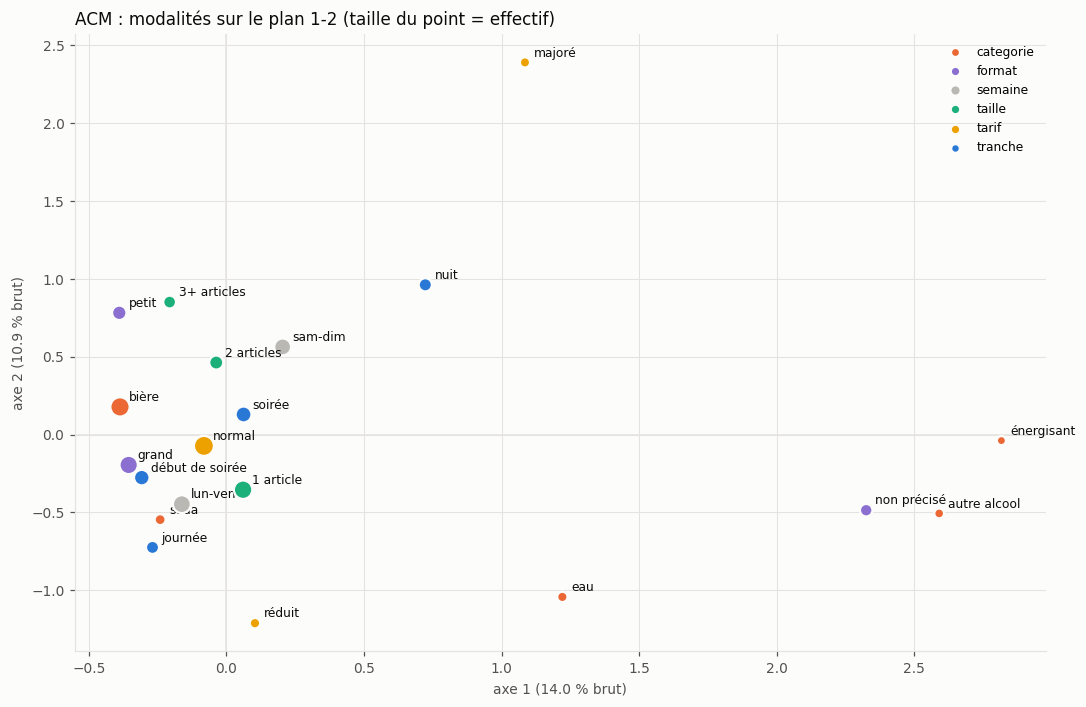

In [48]:
coord = coord_modalites.iloc[:, :2].copy()
coord.columns = ["axe1", "axe2"]
coord["variable"] = coord.index.str.split(" = ").str[0]
coord["modalite"] = coord.index.str.split(" = ").str[1]
COULEUR_VARIABLE = {"tranche": BLEU, "semaine": NEUTRE, "categorie": ORANGE, "taille": VERT, "format": "#8a6fd1", "tarif": JAUNE}

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.axhline(0, color=GRILLE, linewidth=1)
ax.axvline(0, color=GRILLE, linewidth=1)
for variable, g in coord.groupby("variable"):
    ax.scatter(g["axe1"], g["axe2"], s=np.sqrt(effectifs[g.index]) * 4, color=COULEUR_VARIABLE[variable], label=variable,
               edgecolor=FOND, linewidth=1.5, zorder=3)
    for nom, ligne in g.iterrows():
        ax.annotate(ligne["modalite"], (ligne["axe1"], ligne["axe2"]), xytext=(6, 4), textcoords="offset points", fontsize=8, color=TEXTE)
ax.legend(frameon=False, loc="upper right", fontsize=8, markerscale=0.6)
ax.set(title="ACM : modalités sur le plan 1-2 (taille du point = effectif)",
       xlabel=f"axe 1 ({acm.percentage_of_variance_[0]:.1f} % brut)",
       ylabel=f"axe 2 ({acm.percentage_of_variance_[1]:.1f} % brut)")
fig.tight_layout()
plt.show()

Après correction de Benzécri, les deux premiers axes portent 91 % de l'information utile (69,5 % et 21,1 %). Le plan 1-2 suffit donc.

**Axe 1 : le type de boisson.** Il est construit à 87 % par la catégorie et le format. Il oppose la bière en format connu (à gauche, v-test -32) aux autres alcools, énergisants et eaux (à droite, v-tests +28, +26 et +15), dont le format n'est pas précisé (+42). Cet axe est en partie mécanique : catégorie et format sont tous deux tirés du libellé, et les produits sans format sont justement les alcools forts et les énergisants. La nuit y est du côté des alcools forts (v-test +15), ce qui retrouve le glissement nocturne de la section 4.2.

**Axe 2 : le moment et la façon de commander.** C'est l'axe le plus instructif, car il rassemble des variables de natures différentes :

- **En haut :** tarif majoré (v-test +28), fin de semaine (+23), nuit (+20), petit format (+20) et commandes de 3 articles ou plus (+16). C'est la commande du samedi soir, en petites bouteilles prises par plusieurs.
- **En bas :** commande d'un seul article (-22), semaine (-23), tarif réduit (-15), journée (-15) et eau (-12). C'est l'achat simple, au tarif réduit.

L'ACM retrouve donc ensemble, sans les avoir cherchés, trois résultats bivariés : la majoration du samedi nuit (3.1), le tarif réduit des commandes d'un seul produit (3.2) et l'achat en nombre des petits formats (3.5).

**Limite :** les axes 3 et suivants ne portent que 9 % de l'information corrigée. Et comme pour l'ACP, ces axes décrivent des profils de commande, pas des groupes de clients : le fichier n'a pas d'identifiant client.

## 5. Synthèse

**Qualité des données**

| Constat | Décision |
|---|---|
| 6 commandes sans date, toutes au libellé ancien (Fisher p ≈ 2e-10) | Exclues des analyses temporelles, pas d'imputation |
| Commande de test `CW1213050` (`Test Park`, prix 9 771) | Retirée |
| 75 libellés pour 61 produits (casse, espaces, Kankpe/Kanpke) | Clé commune ; format et catégorie dérivés des noms |
| Deux fiches de la Kankpe 65cl avec des règles de prix différentes | À signaler au gestionnaire du catalogue |
| Démarrage du 5 au 8 octobre, extraction le 27 en cours de journée | Période d'étude : 18 soirées, du 9 au 26 octobre |
| Une commande peut avoir plusieurs lignes | Deux niveaux d'analyse : la ligne et la commande |

**Ce que disent les données**

1. **Un panier typique : une grande bière à 600.** 35 % des commandes valent exactement 600, et 82 % n'ont qu'un produit. Le montant est très asymétrique (moyenne 976, médiane 600). La bière fait 79 % du chiffre, et Flag 65cl 16 % des articles à elle seule (Gini 0,71).
2. **Une activité nocturne et de fin de semaine.** 80 % des commandes tombent entre 18 h et 2 h (heure moyenne 21 h 11). Les soirées du samedi et du dimanche ont 1,6 fois plus de commandes (p = 0,003 sur 18 soirées). Le khi2 sur les commandes exagère cet effet : la bonne unité est la soirée.
3. **Le prix d'un produit n'est pas fixe.** Le samedi entre 22 h et 6 h, 58 % des lignes sont majorées de +100, contre 0,1 % le reste du temps (odds ratio ≈ 1 100). L'heure de début varie (22 h 01 à 23 h 00). Les réductions (-100 à -200, sur 4 produits) touchent presque seulement les commandes d'un seul produit (58 % contre 3 %, odds ratio ≈ 47).
4. **Le moment change le prix payé, pas la quantité.** La nuit coûte plus cher par article, et c'est entièrement dû à la majoration : à prix de référence, l'écart disparaît (p = 0,24). La taille du panier ne dépend ni de l'heure ni du jour.
5. **La nuit, plus d'alcool fort et d'énergisants.** Leur part est environ 2,5 fois plus élevée la nuit, en semaine comme en fin de semaine (odds ratio de Mantel-Haenszel 2,54 [1,82 ; 3,56], homogène).
6. **Les petits formats s'achètent par plusieurs** (44 % contre 17 % pour les grands), et les clients mélangent peu les formats et les catégories. Aucune paire de produits n'est privilégiée une fois l'artefact de l'ancien catalogue retiré.
7. **En multivarié, deux dimensions :** la taille du panier et le prix par article (ACP, 81 %), puis le type de boisson et le profil « samedi soir » contre « achat simple » (ACM, 91 % corrigé).

**Limites**

- Trois semaines de données seulement : 2 ou 3 soirées par jour de la semaine, et aucune saisonnalité observable.
- Pas d'identifiant client : impossible de distinguer un client fidèle d'un nouveau client, ou de suivre des habitudes.
- La catégorie et le format sont déduits des libellés : ce sont des choix d'analyse, pas des données du fichier.
- Les causes de la majoration et des réductions ne sont pas dans les données. Les explications proposées sont des hypothèses à vérifier auprès de l'exploitant.
- Tous les résultats décrivent des associations, pas des causes.